# Dungeon Master v2: Arquitectura Multi-Agente con Expansión Dinámica del Mundo

**Proyecto Final — NLP (MMIA 6021 4889)**  
**Pablo Encalada**  
**Octubre 2026**

---

## 1. Problema y motivación

En la **v1** demostramos que un agente LangGraph con herramientas supera a un LLM directo en consistencia narrativa (+20 puntos en LLM-as-judge). Sin embargo, el mundo era **estático**: 5 ubicaciones fijas, NPCs predefinidos, sin posibilidad de expansión.

En un juego de D&D real, el DM **inventa** nuevas locaciones, personajes y objetos sobre la marcha cuando el jugador explora. "Busco una puerta escondida" debería generar una nueva rama de la historia, no un "no hay nada aquí".

### Diseño experimental v2

| | v1 (Agente simple) | v2 (Multi-agente) |
|---|---|---|
| **Arquitectura** | 1 nodo agente + ToolNode | 3 nodos especializados: Narrator, WorldBuilder, Coherence |
| **Mundo** | Estático (5 ubicaciones fijas) | Dinámico (se expande con `create_location`, `create_npc`, `create_item`) |
| **Flujo** | agent → tools → agent | narrator → ¿expandir? → world_builder → coherence → narrator |
| **Evaluación** | Keywords + LLM-as-judge | Misma + métricas de expansión (nuevas zonas creadas, coherencia del mundo expandido) |

In [1]:
import time, random, re, json, textwrap, copy, math, unicodedata
from typing import Annotated, TypedDict, Literal
from collections import Counter
import networkx as nx

import pandas as pd
import matplotlib.pyplot as plt

from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode

from openai import OpenAI

print("Imports OK")

Imports OK


In [2]:
# ────────────────────────────────────────────────────────────────────────────
# Configuración del LLM
# ────────────────────────────────────────────────────────────────────────────

OLLAMA_MODEL = "qwen2.5:latest"  # 7B Q4_K_M
OLLAMA_BASE_URL = "http://127.0.0.1:11500"
EMBED_MODEL = "bge-m3"  # embeddings multilingües (ollama pull bge-m3)
EMBED_BASE_URL = OLLAMA_BASE_URL
JUDGE_MODEL = "qwen2.5:72b"  # el juez debe ser más grande que el modelo evaluado (Semana 2 Clase 3)

llm = ChatOllama(model=OLLAMA_MODEL, base_url=OLLAMA_BASE_URL, temperature=0.7)
llm_creative = ChatOllama(model=OLLAMA_MODEL, base_url=OLLAMA_BASE_URL, temperature=0.9)  # más creativo para WorldBuilder
llm_strict = ChatOllama(model=OLLAMA_MODEL, base_url=OLLAMA_BASE_URL, temperature=0.1)    # más determinista para Coherence

try:
    resp = llm.invoke("Di solo OK")
    print(f"Ollama conectado. Modelo: {OLLAMA_MODEL}")
    print(f"Tres perfiles de temperatura: narrator=0.7, world_builder=0.9, coherence=0.1")
except Exception as e:
    print(f"ERROR: {e}")

Ollama conectado. Modelo: qwen2.5:latest
Tres perfiles de temperatura: narrator=0.7, world_builder=0.9, coherence=0.1


## 2. Mundo dinámico

El mundo inicial es el mismo que v1 (5 ubicaciones), pero ahora el `game_state` incluye un **mundo mutable** que puede crecer durante la partida. Las nuevas ubicaciones, NPCs y objetos creados por el WorldBuilder se registran en `game_state["world"]`.

In [3]:
# ────────────────────────────────────────────────────────────────────────────
# Definición del mundo (inicial — puede crecer dinámicamente)
# ────────────────────────────────────────────────────────────────────────────

WORLD_INITIAL = {
    "locations": {
        "taberna": {
            "description": "Una taberna calida con olor a estofado. Un fuego crepita en la chimenea.",
            "connections": ["plaza", "bosque"],
            "items": ["antorcha"],
            "npcs": ["Goruk el tabernero"],
            "dynamic": False,
        },
        "plaza": {
            "description": "La plaza central del pueblo. Una fuente de piedra en el centro.",
            "connections": ["taberna", "herreria", "bosque"],
            "items": [],
            "npcs": ["Elena la comerciante"],
            "dynamic": False,
        },
        "herreria": {
            "description": "El calor del horno es sofocante. Espadas y escudos cuelgan de las paredes.",
            "connections": ["plaza"],
            "items": ["escudo de hierro"],
            "npcs": ["Bron el herrero"],
            "dynamic": False,
        },
        "bosque": {
            "description": "Arboles altos bloquean la luz. Se escuchan ruidos entre la maleza.",
            "connections": ["plaza", "taberna", "cueva"],
            "items": ["hierbas medicinales"],
            "npcs": [],
            "dynamic": False,
        },
        "cueva": {
            "description": "Una cueva oscura y humeda. Huesos viejos esparcidos por el suelo.",
            "connections": ["bosque"],
            "items": ["cofre con 50 monedas de oro"],
            "npcs": ["Goblin centinela"],
            "dynamic": False,
        },
    },
    "npcs": {
        "Goruk el tabernero": {
            "dialogue": "Bienvenido, viajero. Ten cuidado en el bosque.",
            "hostile": False,
        },
        "Elena la comerciante": {
            "dialogue": "Vendo pociones por 10 monedas de oro.",
            "hostile": False,
        },
        "Bron el herrero": {
            "dialogue": "Puedo afilar tu espada por 5 monedas de oro.",
            "hostile": False,
        },
        "Goblin centinela": {
            "dialogue": "¡Intruso! ¡Este es MI tesoro!",
            "hostile": True, "hp": 12, "attack": "1d6", "defense": 10,
        },
    },
}

INITIAL_STATE = {
    "player_name": "Aventurero",
    "hp": 20, "max_hp": 20, "gold": 15,
    "inventory": ["espada oxidada", "pocion de curacion"],
    "location": "taberna",
    "events": [],
    "items_taken": [], "enemies_defeated": [],
}

print("Mundo inicial (5 ubicaciones — puede crecer):")
for loc, data in WORLD_INITIAL["locations"].items():
    conns = ", ".join(data["connections"])
    print(f"  {loc:<12} -> {conns}")

Mundo inicial (5 ubicaciones — puede crecer):
  taberna      -> plaza, bosque
  plaza        -> taberna, herreria, bosque
  herreria     -> plaza
  bosque       -> plaza, taberna, cueva
  cueva        -> bosque


## 3. Herramientas del Narrator + herramientas del WorldBuilder

Separamos las herramientas en dos grupos:
- **Narrator tools**: las mismas de v1 (`check_state`, `move_to`, `attack_enemy`, etc.)
- **WorldBuilder tools**: nuevas herramientas para expandir el mundo (`create_location`, `create_npc`, `create_item`)

In [4]:
# ────────────────────────────────────────────────────────────────────────────
# Estado mutable del juego + mundo dinámico
# ────────────────────────────────────────────────────────────────────────────

game_state = {}
world = {}  # mundo mutable (copia de WORLD_INITIAL + expansiones)


def reset_game():
    """Reinicia estado del jugador y mundo."""
    global game_state, world
    game_state = {
        "hp": INITIAL_STATE["hp"], "max_hp": INITIAL_STATE["max_hp"],
        "gold": INITIAL_STATE["gold"],
        "inventory": list(INITIAL_STATE["inventory"]),
        "location": INITIAL_STATE["location"],
        "events": [], "items_taken": [], "enemies_defeated": [],
        "locations_created": [],  # tracking de expansiones
        "npcs_created": [],
        "items_created": [],
        "turn": 0,          # contador de jugadas (para fechar lo creado)
        "chronicle": "",    # crónica: resumen de lo que salió de la ventana de contexto
    }
    world = copy.deepcopy(WORLD_INITIAL)
    # Registro del mundo: cada entidad guarda sus características, dónde está,
    # cuándo se creó y su estado. Vive en Python, no en el contexto del LLM.
    for loc, data in world["locations"].items():
        data.setdefault("created_turn", 0)
        for npc in data["npcs"]:
            world["npcs"][npc].update({"location": loc, "status": "presente",
                                       "dynamic": False, "created_turn": 0})
            world["npcs"][npc].setdefault("description", world["npcs"][npc]["dialogue"])
    world["items"] = {}
    for loc, data in world["locations"].items():
        for item in data["items"]:
            world["items"][item] = {"description": "", "location": loc,
                                    "status": "en el lugar", "dynamic": False, "created_turn": 0}


def _roll(notation: str) -> int:
    notation = notation.strip().lower()
    m = re.match(r"(\d+)d(\d+)([+-]\d+)?", notation)
    if not m:
        return random.randint(1, 20)
    n, sides, mod = int(m.group(1)), int(m.group(2)), int(m.group(3) or 0)
    return sum(random.randint(1, sides) for _ in range(n)) + mod


def _state_summary() -> str:
    inv = ", ".join(game_state["inventory"]) if game_state["inventory"] else "(vacio)"
    return (
        f"[HP: {game_state['hp']}/{game_state['max_hp']} | "
        f"Oro: {game_state['gold']} | "
        f"Ubicacion: {game_state['location']} | "
        f"Inventario: {inv}]"
    )


def _world_summary() -> str:
    locs = list(world["locations"].keys())
    dynamic = [l for l, d in world["locations"].items() if d.get("dynamic")]
    return f"Ubicaciones: {len(locs)} ({len(dynamic)} creadas dinámicamente): {', '.join(locs)}"


def _world_memory() -> str:
    """Memoria compacta del mundo para los system prompts.
    Siempre incluye lo creado dinámicamente, los NPCs y la crónica,
    aunque los mensajes donde ocurrió ya no estén en la ventana de contexto."""
    lines = []
    dyn_locs = [(k, v) for k, v in world["locations"].items() if v.get("dynamic")]
    if dyn_locs:
        lines.append("Lugares descubiertos:")
        for k, v in dyn_locs:
            lines.append(f"- {k} (jugada {v['created_turn']}, conecta con {', '.join(v['connections'])}): "
                         f"{v['description'][:100]}")
    dyn_npcs = [(k, v) for k, v in world["npcs"].items() if v.get("dynamic")]
    if dyn_npcs:
        lines.append("Personajes creados:")
        for k, v in dyn_npcs:
            lines.append(f"- {k} en {v['location']} ({'hostil' if v['hostile'] else 'amigable'}, "
                         f"{v['status']}): {v['description'][:80]}")
    dyn_items = [(k, v) for k, v in world["items"].items() if v.get("dynamic")]
    if dyn_items:
        lines.append("Objetos creados: " + "; ".join(f"{k} ({v['location']}, {v['status']})"
                                                      for k, v in dyn_items))
    if game_state["chronicle"]:
        lines.append(f"Crónica:\n{game_state['chronicle']}")
    return "\n".join(lines) or "(nada creado todavía)"


def _similar_location(key: str):
    """Devuelve una ubicación existente con nombre casi igual (evita duplicados)."""
    words = set(key.split("_"))
    for existing in world["locations"]:
        ex_words = set(existing.split("_"))
        overlap = len(words & ex_words) / max(len(words | ex_words), 1)
        if overlap >= 0.5 and world["locations"][existing].get("dynamic"):
            return existing
    return None


# ── Narrator tools (mismas de v1) ──────────────────────────────────────────

@tool
def roll_dice(notation: str) -> str:
    """Tira dados con notacion estandar (ej: '1d20', '2d6+3')."""
    return f"Tiraste {notation}: resultado = {_roll(notation)}"


@tool
def check_state() -> str:
    """Consulta el estado actual del jugador: HP, oro, inventario, ubicacion y conexiones."""
    loc = game_state["location"]
    loc_data = world["locations"][loc]
    available_items = [i for i in loc_data["items"] if i not in game_state["items_taken"]]
    npcs_here = [n for n in loc_data["npcs"] if n not in game_state["enemies_defeated"]]
    connections = ", ".join(loc_data["connections"])
    return (
        f"Estado del jugador: {_state_summary()}\n"
        f"Descripcion del lugar: {loc_data['description']}\n"
        f"Objetos aqui: {available_items or 'ninguno'}\n"
        f"NPCs aqui: {npcs_here or 'nadie'}\n"
        f"Puedes ir a: {connections}\n"
        f"Eventos previos: {game_state['events'][-5:] if game_state['events'] else 'ninguno'}\n"
        f"Mundo: {_world_summary()}"
    )


@tool
def talk_to(npc_name: str) -> str:
    """Habla con un NPC de la ubicacion actual."""
    loc = game_state["location"]
    npcs_here = [n for n in world["locations"][loc]["npcs"] if n not in game_state["enemies_defeated"]]
    npc = next((n for n in npcs_here if npc_name.strip().lower() in n.lower() or n.lower() in npc_name.lower()), None)
    if not npc:
        return f"No hay nadie llamado '{npc_name}' aqui. NPCs: {npcs_here or 'nadie'}"
    dialogo = world["npcs"][npc].get("dialogue", "...")
    game_state["events"].append(f"Hablo con {npc}: {dialogo}")
    return f'{npc} dice: "{dialogo}"'


@tool
def consult_world(topic: str = "") -> str:
    """Consulta el registro permanente del mundo: lugares descubiertos, personajes, objetos,
    todos los eventos y la cronica de la aventura. Usalo cuando el jugador pregunte por el
    pasado, por lugares o personajes que ya conocio, o pida un resumen. 'topic' filtra
    (ej: 'goblin', 'sendero'); vacio devuelve todo."""
    # Memoria como grafo: con tema → subgrafo relevante; sin tema → resumen global + eventos
    if topic.strip():
        return graph_context(topic)
    eventos = "\n".join(f"{i}. {e}" for i, e in enumerate(game_state["events"], 1))
    return f"EVENTOS EN ORDEN (verdad del juego):\n{eventos}\n\n" + graph_summary()



@tool
def move_to(destination: str) -> str:
    """Mueve al jugador a una ubicacion conectada."""
    dest = destination.strip().lower()
    current = game_state["location"]
    connections = world["locations"][current]["connections"]
    if dest not in connections:
        return f"No puedes ir a '{dest}' desde {current}. Destinos validos: {', '.join(connections)}"
    game_state["location"] = dest
    game_state["events"].append(f"Se movio de {current} a {dest}")
    loc_data = world["locations"][dest]
    npcs = [n for n in loc_data["npcs"] if n not in game_state["enemies_defeated"]]
    items = [i for i in loc_data["items"] if i not in game_state["items_taken"]]
    return (
        f"Te mueves a: {dest}. {loc_data['description']}\n"
        f"NPCs aqui: {npcs or 'nadie'}. Objetos: {items or 'ninguno'}.\n"
        f"{_state_summary()}"
    )


@tool
def pick_up_item(item_name: str) -> str:
    """Recoge un objeto de la ubicacion actual."""
    item = item_name.strip().lower()
    loc = game_state["location"]
    available = [i for i in world["locations"][loc]["items"] if i not in game_state["items_taken"]]
    available_lower = [i.lower() for i in available]
    if item not in available_lower:
        return f"No hay '{item}' aqui. Objetos disponibles: {available or 'ninguno'}"
    idx = available_lower.index(item)
    real_name = available[idx]
    game_state["items_taken"].append(real_name)
    oro = re.search(r"(\d+) monedas de oro", real_name)
    if oro:  # las monedas suman al oro, no van al inventario como objeto
        game_state["gold"] += int(oro.group(1))
        game_state["events"].append(f"Recogio: {real_name} (+{oro.group(1)} de oro)")
        if real_name in world["items"]:
            world["items"][real_name]["status"] = "recogido"
        return f"Recogiste las monedas. Oro total (ya actualizado): {game_state['gold']}. {_state_summary()}"
    game_state["inventory"].append(real_name)
    game_state["events"].append(f"Recogio: {real_name}")
    if real_name in world["items"]:
        world["items"][real_name]["status"] = "en el inventario"
    return f"Recogiste: {real_name}. {_state_summary()}"


@tool
def use_potion() -> str:
    """Usa una pocion de curacion del inventario."""
    if "pocion de curacion" not in game_state["inventory"]:
        return f"No tienes pociones. Inventario: {game_state['inventory']}"
    heal = _roll("2d4+2")
    game_state["inventory"].remove("pocion de curacion")
    old_hp = game_state["hp"]
    game_state["hp"] = min(game_state["hp"] + heal, game_state["max_hp"])
    game_state["events"].append(f"Uso pocion: +{heal} HP ({old_hp} -> {game_state['hp']})")
    return f"Bebiste la pocion. Recuperas {heal} HP. {_state_summary()}"


@tool
def attack_enemy(enemy_name: str) -> str:
    """Resuelve un turno de combate contra un enemigo."""
    loc = game_state["location"]
    npcs_here = [n for n in world["locations"][loc].get("npcs", [])
                 if n not in game_state["enemies_defeated"]]
    enemy = None
    for npc in npcs_here:
        if enemy_name.lower() in npc.lower():
            enemy = npc
            break
    if not enemy:
        return f"No hay enemigo '{enemy_name}' aqui. NPCs: {npcs_here or 'nadie'}"
    npc_data = world["npcs"][enemy]
    if not npc_data.get("hostile", False):
        return f"{enemy} no es hostil."
    player_roll = _roll("1d20")
    player_hits = player_roll >= 10
    player_dmg = _roll("1d6") if player_hits else 0
    enemy_roll = _roll("1d20")
    enemy_hits = enemy_roll >= 10
    enemy_dmg = _roll(npc_data.get("attack", "1d6")) if enemy_hits else 0
    result = f"--- COMBATE vs {enemy} ---\n"
    result += f"Tu ataque: d20={player_roll} -> {'ACIERTO' if player_hits else 'FALLO'}"
    if player_hits:
        result += f", {player_dmg} de dano"
    result += f"\nAtaque de {enemy}: d20={enemy_roll} -> {'ACIERTO' if enemy_hits else 'FALLO'}"
    if enemy_hits:
        game_state["hp"] = max(0, game_state["hp"] - enemy_dmg)
        result += f", {enemy_dmg} de dano a ti"
    if player_hits:
        game_state["enemies_defeated"].append(enemy)
        game_state["events"].append(f"Derroto a {enemy}")
        world["npcs"][enemy]["status"] = "derrotado"
        result += f"\n¡{enemy} ha sido derrotado!"
    else:
        game_state["events"].append(f"Combate con {enemy}: fallo")
        result += f"\n{enemy} sigue en pie."
    result += f"\n{_state_summary()}"
    return result


# ── WorldBuilder tools (NUEVAS en v2) ─────────────────────────────────────

@tool
def create_location(name: str, description: str, connected_to: str) -> str:
    """Crea una nueva ubicacion en el mundo y la conecta a una ubicacion existente.
    Usa esto cuando el jugador descubre un lugar nuevo (puerta escondida, pasadizo, etc.).
    El nombre debe ser en minusculas sin acentos (ej: 'pasadizo_secreto')."""
    key = name.strip().lower().replace(" ", "_")
    # Lo que se descubre está donde está el jugador (si no, sería inalcanzable)
    parent = game_state["location"]
    if key in world["locations"]:
        return f"La ubicacion '{key}' ya existe."
    similar = _similar_location(key)
    if similar:
        return (f"NO CREADA: ya existe '{similar}', muy parecida a '{key}'. "
                f"Reutiliza '{similar}' en vez de duplicarla.")
    if parent not in world["locations"]:
        return f"La ubicacion '{parent}' no existe. Ubicaciones: {list(world['locations'].keys())}"
    world["locations"][key] = {
        "description": description,
        "connections": [parent],
        "items": [],
        "npcs": [],
        "dynamic": True,
        "created_turn": game_state["turn"],
    }
    world["locations"][parent]["connections"].append(key)
    game_state["locations_created"].append(key)
    game_state["events"].append(f"Descubrio nueva ubicacion: {key} (conectada a {parent})")
    return (
        f"NUEVA UBICACION CREADA: '{key}'\n"
        f"Descripcion: {description}\n"
        f"Conectada a: {parent} (bidireccional)\n"
        f"Ahora puedes moverte ahi con move_to.\n"
        f"{_world_summary()}"
    )


@tool
def create_npc(name: str, description: str, location: str, hostile: bool) -> str:
    """Crea un nuevo NPC en una ubicacion. Usa esto para poblar zonas nuevas o añadir
    personajes cuando el jugador busca interaccion."""
    loc = location.strip().lower()
    if loc not in world["locations"]:
        return f"La ubicacion '{loc}' no existe."
    if name in world["npcs"]:
        return f"El NPC '{name}' ya existe."
    npc_data = {"dialogue": description, "description": description, "hostile": hostile,
                "location": loc, "status": "presente", "dynamic": True,
                "created_turn": game_state["turn"]}
    if hostile:
        npc_data.update({"hp": random.randint(8, 15), "attack": "1d6", "defense": 10})
    world["npcs"][name] = npc_data
    world["locations"][loc]["npcs"].append(name)
    game_state["npcs_created"].append(name)
    game_state["events"].append(f"Nuevo NPC: {name} en {loc}")
    return f"NPC CREADO: '{name}' en {loc} ({'hostil' if hostile else 'amigable'}). {description}"


@tool
def create_item(name: str, description: str, location: str) -> str:
    """Crea un nuevo objeto en una ubicacion. Usa esto para añadir tesoros, llaves,
    armas u otros objetos interesantes."""
    loc = location.strip().lower()
    if loc not in world["locations"]:
        return f"La ubicacion '{loc}' no existe."
    world["locations"][loc]["items"].append(name)
    world["items"][name] = {"description": description, "location": loc, "status": "en el lugar",
                            "dynamic": True, "created_turn": game_state["turn"]}
    game_state["items_created"].append(name)
    game_state["events"].append(f"Nuevo objeto: {name} en {loc}")
    return f"OBJETO CREADO: '{name}' en {loc}. {description}"


# Dos conjuntos de herramientas
NARRATOR_TOOLS = [roll_dice, check_state, move_to, pick_up_item, use_potion, attack_enemy, talk_to, consult_world]
V1_TOOLS = [roll_dice, check_state, move_to, pick_up_item, use_potion, attack_enemy]  # v1 sin memoria
WORLD_TOOLS = [create_location, create_npc, create_item, check_state]
ALL_TOOLS = list({t.name: t for t in NARRATOR_TOOLS + WORLD_TOOLS}.values())

print(f"Narrator tools: {[t.name for t in NARRATOR_TOOLS]}")
print(f"WorldBuilder tools: {[t.name for t in WORLD_TOOLS]}")
print(f"Total herramientas únicas: {len(ALL_TOOLS)}")

Narrator tools: ['roll_dice', 'check_state', 'move_to', 'pick_up_item', 'use_potion', 'attack_enemy', 'talk_to', 'consult_world']
WorldBuilder tools: ['create_location', 'create_npc', 'create_item', 'check_state']
Total herramientas únicas: 11


### Memoria del mundo como grafo (GraphRAG local)

El mundo ya es un grafo: lugares conectados, NPCs y objetos que están en un lugar, un jugador que posee, derrota y habla con otros personajes. Guardarlo como grafo (`networkx`) conserva las **relaciones** entre entidades, no solo sus características, aunque salgan de la ventana de contexto.

- **Capa estructural** (sin LLM): se reconstruye del estado del juego en cada jugada → 100% confiable.
- **Capa narrativa** (cronista con salida estructurada): tripletas `(sujeto, relación, objeto)` de lo que solo existió en la narración.
- **Recuperación** (*local search*): entidades semilla (ubicación actual + entidades mencionadas, por nombre o por similitud con embeddings `bge-m3`) → vecindario a 1 salto → texto para el prompt. Si la acción nombra otro lugar, se agrega la **ruta más corta** del grafo (verificable, no inventada).


In [5]:
# ────────────────────────────────────────────────────────────────────────────
# Memoria del mundo como grafo de conocimiento (GraphRAG "local search")
# ────────────────────────────────────────────────────────────────────────────
# El mundo YA es un grafo: lugares conectados, NPCs y objetos que están en un lugar,
# el jugador que posee, derrota, habla con... Guardarlo como grafo conserva las RELACIONES
# entre entidades (no solo sus características) aunque salgan del contexto del LLM.
#
# Dos capas de aristas:
#   - estructural (fuente="herramienta"): se reconstruye del estado del juego en cada jugada.
#     Sin LLM → 100% confiable.
#   - narrativa (fuente="cronista"): tripletas (sujeto, relación, objeto) que el cronista extrae
#     de la narración con salida estructurada (lo que solo existió en el texto: advertencias,
#     pistas, promesas...).
#
# Recuperación (local search de GraphRAG): entidades semilla (ubicación actual + entidades
# mencionadas en la acción, por nombre o por similitud con embeddings bge-m3) → vecindario a
# 1 salto → se serializa como texto para el prompt. Si la acción nombra otro lugar, se agrega
# la ruta más corta (shortest_path), que es verificable.

import networkx as nx
import numpy as np
from langchain_ollama import OllamaEmbeddings

embedder = OllamaEmbeddings(model=EMBED_MODEL, base_url=EMBED_BASE_URL)

G = nx.MultiDiGraph()
narrative_triples = []   # [(sujeto, relación, objeto, jugada)] extraídas por el cronista
_emb_cache = {}          # texto del nodo → embedding (solo se calcula una vez por texto)


def _norm(text):
    """minúsculas, sin acentos, '_' → espacio."""
    t = unicodedata.normalize("NFKD", str(text).lower()).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", t.replace("_", " ")).strip()


def reset_graph():
    global G, narrative_triples, _emb_cache
    G = nx.MultiDiGraph()
    narrative_triples = []


def _add_edge(u, rel, v, fuente="herramienta", **attrs):
    if not G.has_node(u):
        G.add_node(u, tipo="concepto", descripcion="")
    if not G.has_node(v):
        G.add_node(v, tipo="concepto", descripcion="")
    G.add_edge(u, v, rel=rel, fuente=fuente, **attrs)


def sync_graph():
    """Reconstruye la capa estructural desde el estado del juego y agrega la narrativa."""
    G.clear()
    G.add_node("jugador", tipo="jugador",
               descripcion=f"HP {game_state['hp']}/{game_state['max_hp']}, oro {game_state['gold']}")
    for loc, d in world["locations"].items():
        G.add_node(loc, tipo="lugar", descripcion=d["description"], dynamic=d.get("dynamic", False),
                   created_turn=d.get("created_turn", 0))
    for name, d in world["npcs"].items():
        G.add_node(name, tipo="npc", descripcion=d.get("description", d.get("dialogue", "")),
                   hostil=d.get("hostile", False), estado=d.get("status", "presente"),
                   dynamic=d.get("dynamic", False), created_turn=d.get("created_turn", 0))
    for name, d in world["items"].items():
        G.add_node(name, tipo="objeto", descripcion=d.get("description", ""), estado=d.get("status", ""),
                   dynamic=d.get("dynamic", False), created_turn=d.get("created_turn", 0))
    for item in game_state["inventory"]:
        if not G.has_node(item):
            G.add_node(item, tipo="objeto", descripcion="", estado="en el inventario")

    for loc, d in world["locations"].items():
        for other in d["connections"]:
            _add_edge(loc, "conecta_con", other)
    for name, d in world["npcs"].items():
        _add_edge(name, "esta_en", d["location"])
    for name, d in world["items"].items():
        if d.get("status") == "en el lugar":
            _add_edge(name, "esta_en", d["location"])
    _add_edge("jugador", "esta_en", game_state["location"])
    for item in game_state["inventory"]:
        _add_edge("jugador", "posee", item)
    for e in game_state["events"]:
        if m := re.match(r"Derroto a (.+)", e):
            _add_edge("jugador", "derroto", m.group(1))
        elif m := re.match(r"Se movio de (\S+) a (\S+)", e):
            _add_edge("jugador", "visito", m.group(2))
        elif m := re.match(r"Hablo con (.+?): (.+)", e):
            _add_edge("jugador", "hablo_con", m.group(1), dijo=m.group(2))
        elif m := re.match(r"Descubrio nueva ubicacion: (\S+)", e):
            _add_edge("jugador", "descubrio", m.group(1))
        elif m := re.match(r"Uso pocion", e):
            _add_edge("jugador", "uso", "pocion de curacion")

    for s, rel, o, t in narrative_triples:
        _add_edge(_resolve(s) or s, rel, _resolve(o) or o, fuente="cronista", jugada=t)


def _resolve(name):
    """Nodo existente que corresponde a un nombre mencionado ('Goruk' → 'Goruk el tabernero')."""
    n = _norm(name)
    if not n:
        return None
    for node in G.nodes:
        nn = _norm(node)
        if n == nn or (len(n) >= 4 and (n in nn or nn in n)):
            return node
    return None


def _node_text(node):
    d = G.nodes[node]
    return f"{node} ({d.get('tipo', '')}): {d.get('descripcion', '')}"


def _semantic_seeds(text, k=2, umbral=0.55):
    """Nodos cuya descripción se parece a la acción (embeddings bge-m3)."""
    nodes = [n for n in G.nodes if G.nodes[n].get("tipo") in ("lugar", "npc", "objeto")]
    textos = [_node_text(n) for n in nodes]
    nuevos = [t for t in textos if t not in _emb_cache]
    if nuevos:
        for t, e in zip(nuevos, embedder.embed_documents(nuevos)):
            _emb_cache[t] = np.array(e) / np.linalg.norm(e)
    q = np.array(embedder.embed_query(text))
    q = q / np.linalg.norm(q)
    sims = sorted(((float(_emb_cache[t] @ q), n) for t, n in zip(textos, nodes)), reverse=True)
    return [n for s, n in sims[:k] if s >= umbral]


def _edge_txt(u, v, d):
    extra = f' (dijo: "{d["dijo"]}")' if d.get("dijo") else ""
    extra += f" [narración, jugada {d['jugada']}]" if d.get("fuente") == "cronista" else ""
    return f"{u} —{d['rel']}→ {v}{extra}"


def _descubiertos_txt():
    """Lugares creados en la partida, numerados y delimitados (evita que el modelo los mezcle:
    'lost in the middle'). No cuenta los lugares ya conocidos que solo se visitaron."""
    desc = [(n, d) for n, d in G.nodes(data=True) if d.get("dynamic") and d.get("tipo") == "lugar"]
    if not desc:
        return "Lugares DESCUBIERTOS en la aventura: 0 (ninguno)"
    bloques = [f"  [{i}] {n} | se llega desde: {world['locations'][n]['connections'][0]} | "
               f"jugada {d.get('created_turn')} | {d.get('descripcion', '')[:90]}"
               for i, (n, d) in enumerate(sorted(desc, key=lambda x: x[1].get("created_turn", 0)), 1)]
    return f"Lugares DESCUBIERTOS en la aventura: {len(desc)}\n" + "\n".join(bloques)


def graph_context(accion, max_aristas=30):
    """Subgrafo relevante a la acción, serializado como texto (local search)."""
    sync_graph()
    loc = game_state["location"]
    semillas = {"jugador", loc}
    for node in G.nodes:  # entidades mencionadas por nombre
        nn = _norm(node)
        if len(nn) >= 4 and (nn in _norm(accion) or any(w in _norm(accion).split() for w in nn.split() if len(w) >= 5)):
            semillas.add(node)
    try:
        semillas |= set(_semantic_seeds(accion))
    except Exception:
        pass  # sin embeddings, la recuperación por nombre sigue funcionando

    aristas, vistos = [], set()
    for s in semillas:
        for u, v, d in list(G.out_edges(s, data=True)) + list(G.in_edges(s, data=True)):
            key = (u, d["rel"], v)
            if key not in vistos:
                vistos.add(key)
                aristas.append(_edge_txt(u, v, d))
    lineas = [_descubiertos_txt()]
    lineas += ["Entidades relevantes:"] + [f"- {_node_text(n)}" for n in semillas if n != "jugador"]
    lineas += ["Relaciones:"] + [f"- {a}" for a in aristas[:max_aristas]]

    # Rutas: si la acción nombra otro lugar, la ruta más corta (solo por conecta_con)
    lugares = nx.Graph([(u, v) for u, v, d in G.edges(data=True) if d["rel"] == "conecta_con"])
    for destino in [n for n in semillas if G.nodes[n].get("tipo") == "lugar" and n != loc]:
        try:
            lineas.append(f"Ruta más corta de {loc} a {destino}: {' → '.join(nx.shortest_path(lugares, loc, destino))}")
        except (nx.NetworkXNoPath, nx.NodeNotFound):
            lineas.append(f"No hay ruta conocida de {loc} a {destino}.")
    return "\n".join(lineas)


def graph_summary():
    """Resumen global: lo creado dinámicamente + relaciones narrativas (para 'recordar' sin tema)."""
    sync_graph()
    lineas = [_descubiertos_txt()]
    lineas += [f"- {_node_text(n)}" for n, d in G.nodes(data=True) if d.get("dynamic")]
    lineas += [f"- {_edge_txt(u, v, d)}" for u, v, d in G.edges(data=True)
               if d.get("fuente") == "cronista" or d["rel"] in ("derroto", "hablo_con")]
    return "\n".join(lineas) or "(nada registrado todavía)"


def draw_graph(ax=None, titulo="Grafo del mundo"):
    """Dibuja el grafo: color por tipo de entidad, borde grueso = creado dinámicamente."""
    sync_graph()
    colores = {"lugar": "#64B5F6", "npc": "#FFB74D", "objeto": "#AED581", "jugador": "#E57373", "concepto": "#CE93D8"}
    H = nx.DiGraph()
    for u, v, d in G.edges(data=True):
        if not H.has_edge(u, v):
            H.add_edge(u, v, rel=d["rel"])
    H.add_nodes_from(G.nodes(data=True))
    if ax is None:
        _, ax = plt.subplots(figsize=(14, 10))
    pos = nx.spring_layout(H, seed=7, k=1.2)
    nx.draw_networkx_nodes(H, pos, ax=ax, node_size=900,
                           node_color=[colores.get(H.nodes[n].get("tipo"), "#BDBDBD") for n in H],
                           linewidths=[3 if H.nodes[n].get("dynamic") else 0.5 for n in H], edgecolors="#333")
    nx.draw_networkx_labels(H, pos, ax=ax, font_size=8)
    nx.draw_networkx_edges(H, pos, ax=ax, alpha=0.5, arrows=True, arrowsize=10)
    nx.draw_networkx_edge_labels(H, pos, ax=ax, font_size=6,
                                 edge_labels={(u, v): d["rel"] for u, v, d in H.edges(data=True)})
    ax.set_title(titulo)
    ax.axis("off")
    return ax


print("Grafo de conocimiento listo (networkx + embeddings bge-m3 para entidades semilla)")


Grafo de conocimiento listo (networkx + embeddings bge-m3 para entidades semilla)


## 4. Grafo Multi-Agente LangGraph

El grafo tiene 3 nodos especializados:

```
START → narrator → should_use_tools? → narrator_tools → narrator
                 → should_expand?    → world_builder → wb_tools → coherence_check → narrator
                 → END
```

1. **Narrator**: narra la historia, usa herramientas de juego (check_state, move_to, etc.)
2. **WorldBuilder**: se activa cuando el jugador explora algo nuevo; crea ubicaciones/NPCs/items
3. **CoherenceChecker**: valida que la expansión sea consistente con el mundo existente

In [6]:
# ────────────────────────────────────────────────────────────────────────────
# 4. Grafo Multi-Agente — ReAct estructurado (Pydantic)
# ────────────────────────────────────────────────────────────────────────────
# v1 usa ReAct con tool calling nativo: el modelo puede "escribir" la llamada como texto
# ("CallCheck_state: {...}") en vez de hacerla. Aquí cada paso del ciclo
# Pensamiento → Acción → Observación es una salida estructurada (Pydantic + JSON Schema):
# Ollama restringe la generación al schema, así que la acción SIEMPRE es una herramienta válida.

from pydantic import BaseModel, Field

MAX_PASOS = 4  # pasos ReAct por jugada


class Paso(BaseModel):
    """Un paso del ciclo ReAct."""
    pensamiento: str = Field(description="Razonamiento breve: qué quiere el jugador y qué necesitas saber o hacer.")
    accion: Literal["ver_estado", "mover", "recoger", "atacar", "curarse", "hablar",
                    "tirar_dados", "recordar", "responder"] = Field(
        description="Acción a usar, o 'responder' cuando ya tienes lo necesario para narrar.")
    argumento: str = Field(description=(
        "mover: destino. recoger: objeto. atacar: enemigo. hablar: personaje. tirar_dados: notación (1d20). "
        "recordar: tema (vacío = todo). Vacío para ver_estado, curarse y responder."))


class MoveResult(BaseModel):
    """Resultado explícito de un intento de movimiento (el narrador no tiene que interpretarlo)."""
    success: bool
    message: str
    current_location: str  # SIEMPRE la ubicación real tras el intento


class NuevoContenido(BaseModel):
    """Decisión del WorldBuilder."""
    razon: str = Field(description="Por qué crear (o no) algo nuevo aquí.")
    tipo: Literal["ubicacion", "npc", "objeto", "nada"] = Field(
        description="Qué crear. 'nada' si lo que busca ya existe o no tiene sentido.")
    nombre: str = Field(description="Ubicación: minúsculas sin acentos con _ (ej: pasadizo_secreto). NPC/objeto: nombre propio.")
    descripcion: str = Field(description="1-2 oraciones, fantasía medieval, coherente con el mundo.")
    hostil: bool = Field(default=False, description="Solo NPCs: si es hostil.")


class Veredicto(BaseModel):
    """Decisión del CoherenceChecker."""
    coherente: bool
    problema: str = Field(default="", description="Si no es coherente, qué falla.")


# ── System prompts especializados ─────────────────────────────────────────

SYSTEM_REACT = """\
Eres el Narrator, un Dungeon Master de D&D. Trabajas en pasos: piensas, eliges UNA acción,
ves su resultado (Observación) y repites hasta tener lo necesario; entonces eliges 'responder'.

ACCIONES:
- mover(destino): el jugador pide ir a un lugar ("voy a", "vuelvo a", "entro a"). La herramienta valida si es posible.
- recoger(objeto) · atacar(enemigo) · hablar(personaje) · curarse() con una poción · tirar_dados(notación)
- ver_estado(): dónde está, HP, oro, inventario, qué hay en el lugar, a dónde puede ir.
- recordar(tema): el PASADO — lugares descubiertos, personajes conocidos, quién dijo qué, eventos,
  rutas entre lugares, resumen. Consulta el grafo de memoria del mundo.
- responder: ya tienes la Observación necesaria.

REGLAS:
1. Una PREGUNTA, buscar o examinar NUNCA mueve al jugador.
2. Haz SOLO lo que pide la acción del jugador. Normalmente basta 1 paso y luego 'responder'.
3. No repitas una acción que ya hiciste en esta jugada.

EJEMPLOS (acción del jugador → primer paso):
- "Voy a la cueva." → {"accion": "mover", "argumento": "cueva"}
- "Vuelvo al bosque." → {"accion": "mover", "argumento": "bosque"}
- "Recojo la antorcha." → {"accion": "recoger", "argumento": "antorcha"}
- "Ataco al goblin." → {"accion": "atacar", "argumento": "goblin"}
- "Hablo con Goruk." → {"accion": "hablar", "argumento": "Goruk"}
- "Uso mi poción de curación." → {"accion": "curarse", "argumento": ""}
- "¿Cuántos HP tengo?" → {"accion": "ver_estado", "argumento": ""}
- "¿Dónde estoy exactamente?" → {"accion": "ver_estado", "argumento": ""}
- "Miro a mi alrededor." → {"accion": "ver_estado", "argumento": ""}
- "¿Qué lugares descubrí?" → {"accion": "recordar", "argumento": "lugares"}
- "Resume la aventura." → {"accion": "recordar", "argumento": ""}
- "¿Quién me habló del bosque?" → {"accion": "recordar", "argumento": "bosque"}
- "¿Cómo llego a la cueva desde aquí?" → {"accion": "recordar", "argumento": "cueva"}
- "Busco una puerta escondida." → {"accion": "ver_estado", "argumento": ""} (el DESCUBRIMIENTO, si lo hay, ya aparece en los pasos)
Después de la Observación → {"accion": "responder", "argumento": ""}"""

SYSTEM_NARRADOR = """\
Eres un Dungeon Master de D&D que narra en español.
Narra en 2-4 oraciones lo que pasó, basándote SOLO en las Observaciones de las herramientas y en
la MEMORIA DEL MUNDO (grafo): son la verdad del juego. No infieras detalles adicionales.
REGLAS:
1. MOVIMIENTO RECHAZADO → NUNCA narres un desplazamiento: di que no puede ir y dónde sigue.
2. No narres acciones que no aparecen en las Observaciones (recoger, hablar, atacar...).
3. Usa EXACTAMENTE los números del estado (HP, oro). NUNCA los recalcules ni sumes.
4. Menciona solo personajes que la memoria ubica en el lugar actual.
5. Si hay un DESCUBRIMIENTO, nárralo. Si el jugador pregunta cómo llegar y hay "Ruta más corta",
   da EXACTAMENTE esa ruta.
6. PREGUNTA del jugador (¿...?) → respóndela; no narres que se mueve ni que hace algo.
7. Resumen de la aventura → sigue los EVENTOS en orden, sin agregar nada.
8. Lugares descubiertos → usa la lista numerada tal cual (nombre, dónde está), sin mezclarlos.
No inventes lugares, objetos, personajes, rutas ni números. Termina mostrando el estado:
[HP: X/20 | Oro: X | Ubicacion: X | Inventario: ...]"""

SYSTEM_WORLD_BUILDER = """\
Eres el WorldBuilder, un diseñador de mundos de D&D. El jugador está buscando o explorando algo.
Decide si tiene sentido crear UNA cosa nueva en su ubicación actual: una ubicación (pasadizo,
sendero, sótano...), un NPC o un objeto.
- Si lo que busca ya existe en la MEMORIA DEL MUNDO, o no tiene sentido, tipo = 'nada'.
- No dupliques lugares existentes con otro nombre.
- Mantén el tono: fantasía medieval, coherente con lo que ya existe.

EJEMPLOS (acción del jugador → decisión):
- "Examino las paredes de la cueva buscando pasadizos." → ubicacion: pasadizo_secreto
- "Busco un sendero escondido entre los árboles." → ubicacion: sendero_escondido
- "Busco a alguien interesante que no haya visto antes." → npc: un personaje nuevo con nombre propio
- "Busco una puerta escondida detrás de la barra." → ubicacion: sotano_de_la_taberna
- "Busco algo de valor en el suelo." → objeto
- "Busco el pasadizo que ya encontré." → nada (ya existe)"""

SYSTEM_COHERENCE = """\
Eres el verificador de coherencia de un mundo de D&D. Te muestran el mundo actual y una
creación nueva. Es INCOHERENTE si: duplica un lugar existente, contradice la memoria del mundo,
o no encaja con la ubicación donde se creó. En otro caso es coherente."""


# ── LLMs con salida estructurada ──────────────────────────────────────────

llm_narrador = ChatOllama(model=OLLAMA_MODEL, base_url=OLLAMA_BASE_URL, temperature=0.4)  # menos adorno que 0.7
llm_planner = ChatOllama(model=OLLAMA_MODEL, base_url=OLLAMA_BASE_URL, temperature=0.3)
planner = llm_planner.with_structured_output(Paso, method="json_schema", include_raw=True)
world_builder_llm = llm_creative.with_structured_output(NuevoContenido, method="json_schema")
coherence_llm = llm_strict.with_structured_output(Veredicto, method="json_schema")

# acción del planner → (herramienta, nombre del parámetro)
ACCIONES = {"ver_estado": (check_state, None), "mover": (move_to, "destination"),
            "recoger": (pick_up_item, "item_name"), "atacar": (attack_enemy, "enemy_name"),
            "curarse": (use_potion, None), "tirar_dados": (roll_dice, "notation"),
            "hablar": (talk_to, "npc_name"), "recordar": (consult_world, "topic")}

EXPLORACION = re.compile(r"busc|examin|explor|investig|escondid|secret|ocult|rastre", re.IGNORECASE)
PREGUNTA_RUTA = re.compile(r"c[oó]mo (llego|vuelvo|voy|regreso)|por d[oó]nde|qu[eé] lugares .*pasar|\bruta\b", re.IGNORECASE)
MOVIMIENTO = re.compile(r"^\s*(voy|vuelvo|regreso|entro|camino|me muevo|ir a)\b", re.IGNORECASE)


def _resolver_destino(destino):
    """'abertura' → 'pasadizo_secreto' si alguna conexión lo menciona en su nombre o descripción;
    si no, se deja igual (move_to lo rechazará con los destinos válidos)."""
    d = _norm(destino)
    conexiones = world["locations"][game_state["location"]]["connections"]
    if not d or d.replace(" ", "_") in conexiones:
        return destino
    for c in conexiones:
        if d in _norm(c) or any(w in _norm(world["locations"][c]["description"]).split() for w in d.split() if len(w) >= 5):
            return c
    return destino


def _location_in(text):
    """Ubicación conocida mencionada en el texto del jugador (sin acentos), o None."""
    t = unicodedata.normalize("NFKD", text.lower()).encode("ascii", "ignore").decode()
    hits = [k for k in world["locations"] if re.search(rf"\b{re.escape(k.replace('_', ' '))}\b", t.replace("_", " "))]
    return max(hits, key=len) if hits else None


class AgentState(TypedDict):
    messages: Annotated[list, add_messages]   # ventana: jugadas anteriores + acción actual
    pasos: list          # [(Paso, observación)] de esta jugada
    expansions: int      # expansiones en esta jugada (máximo 1)
    prompt_tokens: int   # máximo de tokens de prompt en esta jugada


def _discoveries_this_turn():
    """Lo creado en esta jugada, leído del registro del mundo."""
    t = game_state["turn"]
    out = [f"Descubres un lugar nuevo: {k} ({v['description']}). Se llega desde: {', '.join(v['connections'])}."
           for k, v in world["locations"].items() if v.get("dynamic") and v["created_turn"] == t]
    out += [f"Aparece un personaje nuevo en {v['location']}: {k} ({v['description']})."
            for k, v in world["npcs"].items() if v.get("dynamic") and v["created_turn"] == t]
    out += [f"Hay un objeto nuevo en {v['location']}: {k} ({v['description']})."
            for k, v in world["items"].items() if v.get("dynamic") and v["created_turn"] == t]
    return out


def _accion(state):
    return next((m.content for m in reversed(state["messages"]) if isinstance(m, HumanMessage)), "")


def _consulta_grafo(state):
    """Consulta al grafo = acción actual + la anterior. Las preguntas de seguimiento
    ("¿Por qué lugares tengo que pasar?") no nombran entidades: heredan las de la jugada previa."""
    humanas = [m.content for m in state["messages"] if isinstance(m, HumanMessage)]
    return " ".join(humanas[-2:])


def _prompt_planner(state):
    """Un solo mensaje por paso: jugadas anteriores (breves), la acción actual y los pasos ya hechos.
    Repetir la acción del jugador en cada paso evita que el modelo tome la Observación como orden nueva."""
    previas = [(m.content, n.content[:150].replace("\n", " ")) for m, n in
               zip(state["messages"][:-1:2], state["messages"][1:-1:2])]
    lineas = []
    if previas:
        lineas.append("JUGADAS ANTERIORES:\n" + "\n".join(f"- Jugador: {a} → DM: {r}..." for a, r in previas))
    lineas.append(f"ACCIÓN ACTUAL DEL JUGADOR: {_accion(state)}")
    hechos = []
    found = _discoveries_this_turn()
    if found:
        hechos.append("(mundo) DESCUBRIMIENTO: " + " ".join(found))
    hechos += [f"{p.accion}({p.argumento}) → {o}" for p, o in state.get("pasos", [])]
    lineas.append("PASOS YA HECHOS EN ESTA JUGADA:\n" + ("\n".join(f"{i+1}. {h}" for i, h in enumerate(hechos))
                                                         or "(ninguno)"))
    lineas.append("¿Siguiente paso? Si ya tienes lo necesario para responder al jugador, accion = 'responder'.")
    return HumanMessage(content="\n\n".join(lineas))


# ── Nodos del grafo ──────────────────────────────────────────────────────

def pensar_node(state: AgentState):
    """Thought + Action: el planner elige el siguiente paso (salida estructurada)."""
    if len(state.get("pasos", [])) >= MAX_PASOS:
        return {"pasos": state["pasos"] + [(Paso(pensamiento="límite de pasos", accion="responder", argumento=""), "")]}
    system = (SYSTEM_REACT + f"\n\nESTADO: {_state_summary()}\nMUNDO: {_world_summary()}"
              f"\n\nMEMORIA DEL MUNDO (grafo, lo relevante a esta acción):\n{graph_context(_consulta_grafo(state))}")
    out = planner.invoke([SystemMessage(content=system), _prompt_planner(state)])
    paso = out["parsed"] or Paso(pensamiento="(salida inválida)", accion="responder", argumento="")
    accion, previos = _accion(state), state.get("pasos", [])
    if paso.accion == "mover" and (not MOVIMIENTO.search(accion) or any(p.accion == "mover" for p, _ in previos)):
        # Solo se mueve si el jugador lo pidió, y una vez por jugada (preguntar/buscar/atacar no mueven;
        # si el movimiento fue rechazado, no busca otro camino por su cuenta)
        paso = Paso(pensamiento=paso.pensamiento, accion="ver_estado" if not previos else "responder", argumento="")
    destino = _location_in(accion)
    if (paso.accion == "responder" and not previos and destino and MOVIMIENTO.search(accion)):
        # El jugador nombra un lugar y pide ir: si el planner responde sin moverlo, mover (la herramienta valida)
        paso = Paso(pensamiento=paso.pensamiento, accion="mover", argumento=destino)
    if paso.accion == "responder" and not previos and not _discoveries_this_turn():
        # Nunca narrar con cero observaciones: primero mirar el estado real
        paso = Paso(pensamiento=paso.pensamiento, accion="ver_estado", argumento="")
    if any(p.accion == paso.accion and p.argumento.strip().lower() == paso.argumento.strip().lower()
           for p, _ in previos):
        paso = Paso(pensamiento=paso.pensamiento, accion="responder", argumento="")  # repetir no aporta: responder
    tokens = (out["raw"].usage_metadata or {}).get("input_tokens", 0)
    return {"pasos": state.get("pasos", []) + [(paso, None)],
            "prompt_tokens": max(state.get("prompt_tokens", 0), tokens)}


def actuar_node(state: AgentState):
    """Action → Observation: el código ejecuta la herramienta elegida."""
    paso, _ = state["pasos"][-1]
    tool_fn, arg_name = ACCIONES[paso.accion]
    if paso.accion == "mover":
        paso = Paso(pensamiento=paso.pensamiento, accion="mover", argumento=_resolver_destino(paso.argumento))
    args = {arg_name: paso.argumento} if arg_name else {}
    antes = game_state["location"]
    try:
        obs = tool_fn.invoke(args)
    except Exception as e:
        obs = f"Error al usar {paso.accion}: {e}"
    if paso.accion == "mover":
        r = MoveResult(success=game_state["location"] != antes, message=obs, current_location=game_state["location"])
        obs = (f"MOVIMIENTO {'EXITOSO' if r.success else 'RECHAZADO'} → el jugador está en: {r.current_location}. "
               f"{r.message}")
    return {"pasos": state["pasos"][:-1] + [(paso, obs)]}


def narrar_node(state: AgentState):
    """Respuesta final en texto libre, basada en las observaciones."""
    obs = [f"- {p.accion}({p.argumento}): {o}" for p, o in state.get("pasos", []) if o]
    found = _discoveries_this_turn()
    if found:
        obs.insert(0, "- DESCUBRIMIENTO: " + " ".join(found))
    memoria = graph_context(_consulta_grafo(state))
    # La ruta del grafo (shortest_path) entra como observación SOLO si el jugador pregunta cómo llegar
    # (si no, el narrador la contaba como un viaje hecho aunque move_to hubiera rechazado el movimiento)
    if PREGUNTA_RUTA.search(_consulta_grafo(state)):
        obs += [f"- grafo: {l}" for l in memoria.splitlines() if l.startswith(("Ruta más corta", "No hay ruta"))]
    contexto = ("Observaciones de esta jugada:\n" + ("\n".join(obs) or "(ninguna)") +
                f"\n\nMEMORIA DEL MUNDO (grafo, relevante a la acción):\n{memoria}")
    response = llm_narrador.invoke([SystemMessage(content=SYSTEM_NARRADOR)] + state["messages"] + [HumanMessage(content=contexto)])
    return {"messages": [AIMessage(content=response.content)]}


def world_builder_node(state: AgentState):
    """WorldBuilder: decide si crear UNA cosa nueva (salida estructurada) y el código la crea."""
    loc = game_state["location"]
    system = (SYSTEM_WORLD_BUILDER + f"\n\nMUNDO ACTUAL: {_world_summary()}"
              f"\nLUGARES CREADOS: {_world_memory()}"
              f"\nMEMORIA DEL MUNDO (grafo):\n{graph_context(_consulta_grafo(state))}"
              f"\nUBICACION ACTUAL: {loc} - {world['locations'][loc]['description']}")
    try:
        c = world_builder_llm.invoke([SystemMessage(content=system), HumanMessage(content=_accion(state))])
    except Exception:
        c = None
    if c and c.tipo != "nada" and c.nombre.strip():
        if c.tipo == "ubicacion":
            create_location.invoke({"name": c.nombre, "description": c.descripcion, "connected_to": loc})
        elif c.tipo == "npc":
            create_npc.invoke({"name": c.nombre, "description": c.descripcion, "location": loc, "hostile": c.hostil})
        else:
            create_item.invoke({"name": c.nombre, "description": c.descripcion, "location": loc})
    return {"expansions": 1}


def _undo_creations():
    """Deshace lo creado en esta jugada (si Coherence lo rechaza)."""
    t = game_state["turn"]
    for k in [k for k, v in world["locations"].items() if v.get("dynamic") and v["created_turn"] == t]:
        for other in world["locations"][k]["connections"]:
            world["locations"][other]["connections"].remove(k)
        del world["locations"][k]
        game_state["locations_created"].remove(k)
    for k in [k for k, v in world["npcs"].items() if v.get("dynamic") and v["created_turn"] == t]:
        world["locations"][world["npcs"][k]["location"]]["npcs"].remove(k)
        del world["npcs"][k]
        game_state["npcs_created"].remove(k)
    for k in [k for k, v in world["items"].items() if v.get("dynamic") and v["created_turn"] == t]:
        world["locations"][world["items"][k]["location"]]["items"].remove(k)
        del world["items"][k]
        game_state["items_created"].remove(k)


def coherence_node(state: AgentState):
    """CoherenceChecker: valida lo creado; si es incoherente, se deshace."""
    found = _discoveries_this_turn()
    if not found:
        return {}
    mundo = json.dumps({k: {"desc": v["description"][:60], "conn": v["connections"]}
                        for k, v in world["locations"].items()}, ensure_ascii=False)
    try:
        v = coherence_llm.invoke([SystemMessage(content=SYSTEM_COHERENCE), HumanMessage(
            content=f"Mundo: {mundo}\nMemoria (grafo):\n{graph_context(game_state['location'])}"
                    f"\n\nCreación nueva: {' '.join(found)}")])
    except Exception:
        v = None
    if v and not v.coherente:
        _undo_creations()
        game_state["events"].append(f"Coherence rechazó una creación: {v.problema[:80]}")
    return {}


# ── Routing ──────────────────────────────────────────────────────────────

def start_router(state: AgentState):
    """Si el jugador busca/explora, el WorldBuilder actúa primero; el narrator ve el resultado como Observación."""
    return "world_builder" if EXPLORACION.search(_accion(state)) else "pensar"


def pensar_router(state: AgentState):
    paso, _ = state["pasos"][-1]
    return "narrar" if paso.accion == "responder" else "actuar"


# ── Construir el grafo ────────────────────────────────────────────────────

graph = StateGraph(AgentState)
graph.add_node("pensar", pensar_node)
graph.add_node("actuar", actuar_node)
graph.add_node("narrar", narrar_node)
graph.add_node("world_builder", world_builder_node)
graph.add_node("coherence", coherence_node)

graph.add_conditional_edges(START, start_router, {"world_builder": "world_builder", "pensar": "pensar"})
graph.add_edge("world_builder", "coherence")
graph.add_edge("coherence", "pensar")
graph.add_conditional_edges("pensar", pensar_router, {"actuar": "actuar", "narrar": "narrar"})
graph.add_edge("actuar", "pensar")   # ciclo ReAct: observación → nuevo pensamiento
graph.add_edge("narrar", END)

app_v2 = graph.compile()

print("Grafo Multi-Agente v2 (ReAct estructurado) compilado:")
print("  START → (exploración) world_builder → coherence → pensar")
print("  START → pensar → actuar → pensar (ciclo ReAct) → narrar → END")


Grafo Multi-Agente v2 (ReAct estructurado) compilado:
  START → (exploración) world_builder → coherence → pensar
  START → pensar → actuar → pensar (ciclo ReAct) → narrar → END


In [7]:
# ────────────────────────────────────────────────────────────────────────────
# 4.1 Wrapper del agente multi-agente
# ────────────────────────────────────────────────────────────────────────────

WINDOW_PLAYS = 3  # jugadas recientes que el LLM ve completas; lo anterior pasa a la crónica

SYSTEM_CRONISTA = """\
Eres el cronista de una partida de D&D. Te muestran jugadas que van a salir de la memoria
de corto plazo. Extrae los HECHOS CLAVE de la narración que valga la pena recordar:
lugares y cómo son, personajes y lo que dijeron de importante, pistas, promesas, misterios.
- Solo hechos EXPLÍCITOS en las jugadas. No inventes.
- NO incluyas HP, oro ni inventario (eso lo registra el sistema).
- SOLO relaciones donde participa un personaje, lugar u objeto con nombre propio
  (nada de ambiente: olores, luz, fuego, "es agradable"...). Si no hay ninguna, lista vacía.
- Máximo 5 hechos, como tripletas (sujeto, relación, objeto), en español.
Ejemplo: Goruk dice "Ten cuidado en el bosque" → (Goruk, advirtio_sobre, bosque)."""


class Tripleta(BaseModel):
    sujeto: str = Field(description="Entidad (personaje, lugar, objeto). Usa el nombre tal como aparece.")
    relacion: str = Field(description="Verbo en snake_case: advirtio_sobre, vive_en, busca, teme, conoce, prometio...")
    objeto: str = Field(description="Entidad o concepto relacionado.")


class Cronica(BaseModel):
    hechos: list[Tripleta] = Field(description="Hechos clave nuevos como tripletas (máximo 5).")


cronista = llm_strict.with_structured_output(Cronica, method="json_schema")
MAX_HECHOS = 15


def update_chronicle(dropped):
    """Incorpora a la crónica los hechos de las jugadas que salen de la ventana de contexto."""
    texto = "\n".join(f"Jugador: {a}\nDM: {r[:500]}" for a, r in dropped)
    try:
        nuevos = cronista.invoke([SystemMessage(content=SYSTEM_CRONISTA), HumanMessage(content=texto)]).hechos[:5]
    except Exception:
        nuevos = []
    sync_graph()
    for h in nuevos:  # capa narrativa del grafo: solo si el sujeto es un personaje, o ambos extremos existen
        s_, o_ = _resolve(h.sujeto), _resolve(h.objeto)
        tipo_s = G.nodes[s_].get("tipo") if s_ else None
        tipo_o = G.nodes[o_].get("tipo") if o_ else None
        triviales = ("asien", "sonri", "mira", "observ", "salud", "sient", "suspir", "ilumin", "huele")
        if any(t_ in h.relacion.lower() for t_ in triviales):
            continue
        if tipo_s == "npc" or (tipo_s in ("lugar", "objeto", "npc") and tipo_o in ("lugar", "objeto", "npc")):
            t = (s_, h.relacion.strip().lower().replace(" ", "_"), o_ or h.objeto.strip(), game_state["turn"])
            if t[:3] not in [x[:3] for x in narrative_triples]:
                narrative_triples.append(t)
    hechos = [f"{s} —{r}→ {o}" for s, r, o, _ in narrative_triples]
    game_state["chronicle"] = "\n".join(f"- {h}" for h in hechos[-MAX_HECHOS:])


class MultiAgentDM:
    """Dungeon Master multi-agente (ReAct estructurado) con mundo dinámico y memoria persistente.

    Memoria en dos niveles:
      - Corto plazo: el LLM ve solo las últimas WINDOW_PLAYS jugadas (acción + narración),
        así el contexto no crece sin límite.
      - Largo plazo: el registro del mundo (world) y la crónica viven en Python y se inyectan
        en los system prompts / se consultan con consult_world.
    """

    def __init__(self, app):
        self.app = app
        self.history = []         # [(acción, narración)] dentro de la ventana
        self.turn_times = []
        self.context_tokens = []  # tokens de prompt máximos por jugada (para graficar)
        self.react_traces = []    # [(pensamiento, acción, argumento, observación)] por jugada
        self.expansion_log = []   # registro de expansiones
        reset_game()
        reset_graph()

    def play(self, action: str) -> str:
        game_state["turn"] += 1
        window = [m for a, r in self.history for m in (HumanMessage(content=a), AIMessage(content=r))]
        state = {"messages": window + [HumanMessage(content=action)],
                 "pasos": [], "expansions": 0, "prompt_tokens": 0}
        t0 = time.time()
        try:
            result = self.app.invoke(state, {"recursion_limit": 40})
        except Exception as e:  # no romper la partida por un fallo puntual
            result = {**state, "messages": state["messages"] + [AIMessage(content=f"(error del DM: {type(e).__name__})")]}
        self.turn_times.append(time.time() - t0)
        self.context_tokens.append(result.get("prompt_tokens", 0))
        self.react_traces.append([(p.pensamiento, p.accion, p.argumento, o) for p, o in result.get("pasos", [])])

        # Registrar si hubo expansión
        new_locs = [l for l in game_state.get("locations_created", [])
                    if l not in [e.get("location") for e in self.expansion_log]]
        for loc in new_locs:
            self.expansion_log.append({
                "location": loc,
                "turn": len(self.turn_times),
                "description": world["locations"].get(loc, {}).get("description", ""),
            })

        last = result["messages"][-1]
        final = last.content if isinstance(last, AIMessage) and last.content else "(sin respuesta)"

        # Ventana: las últimas jugadas; lo que sale va a la crónica
        self.history.append((action, final))
        if len(self.history) > WINDOW_PLAYS:
            dropped, self.history = self.history[:-WINDOW_PLAYS], self.history[-WINDOW_PLAYS:]
            update_chronicle(dropped)
        return final


# ── Baseline v1 (para comparar) ──────────────────────────────────────────

SYSTEM_PROMPT_BASELINE = """\
Eres un Dungeon Master de D&D. Narras una aventura interactiva en espanol.

MUNDO:
- Ubicaciones: taberna, plaza, herreria, bosque, cueva.
- Taberna conecta con plaza y bosque. Plaza conecta con taberna, herreria y bosque.
  Herreria conecta con plaza. Bosque conecta con plaza, taberna y cueva. Cueva conecta con bosque.
- NPCs: Goruk (taberna), Elena (plaza), Bron (herreria), Goblin (cueva, hostil).

JUGADOR: HP 20/20, Oro 15, Inventario: espada oxidada, pocion de curacion. Ubicacion: taberna.

REGLAS:
- Solo movimiento a ubicaciones conectadas. Combate: d20 >= 10 para acertar, d6 de daño.
- Si el jugador busca algo que no existe, puedes inventarlo de forma coherente.
- Narra brevemente (3-4 oraciones). Muestra [HP: X/20 | Oro: X | Ubicacion: X | Inventario: ...]"""


class BaselineDM:
    def __init__(self, llm):
        self.llm = llm
        self.messages = [SystemMessage(content=SYSTEM_PROMPT_BASELINE)]
        self.turn_times = []

    def play(self, action: str) -> str:
        self.messages.append(HumanMessage(content=action))
        t0 = time.time()
        response = self.llm.invoke(self.messages)
        self.turn_times.append(time.time() - t0)
        self.messages.append(response)
        return response.content


# ── Agente v1 simple (para comparar) ────────────────────────────────────

SYSTEM_PROMPT_V1 = """\
Eres un Dungeon Master de D&D. Narras una aventura interactiva en español.
INSTRUCCIONES OBLIGATORIAS:
1. SIEMPRE llama a check_state PRIMERO.
2. Si el jugador quiere MOVERSE, usa move_to.
3. Si el jugador quiere RECOGER, usa pick_up_item.
4. Si el jugador quiere ATACAR, usa attack_enemy.
5. Si el jugador quiere CURARSE, usa use_potion.
6. Para dados, usa roll_dice.
NUNCA respondas sin usar check_state primero."""

llm_v1_tools = llm.bind_tools(V1_TOOLS)

class V1State(TypedDict):
    messages: Annotated[list, add_messages]


def v1_agent_node(state: V1State):
    state_info = _state_summary()
    system = SYSTEM_PROMPT_V1 + f"\n\nESTADO: {state_info}"
    messages = [SystemMessage(content=system)] + state["messages"]
    response = llm_v1_tools.invoke(messages)
    return {"messages": [response]}

def v1_should_continue(state: V1State):
    last = state["messages"][-1]
    if hasattr(last, "tool_calls") and last.tool_calls:
        return "tools"
    return END

v1_tool_node = ToolNode(V1_TOOLS)
graph_v1 = StateGraph(V1State)
graph_v1.add_node("agent", v1_agent_node)
graph_v1.add_node("tools", v1_tool_node)
graph_v1.add_edge(START, "agent")
graph_v1.add_conditional_edges("agent", v1_should_continue, {"tools": "tools", END: END})
graph_v1.add_edge("tools", "agent")
app_v1 = graph_v1.compile()


class AgentDMv1:
    def __init__(self, app):
        self.app = app
        self.state = {"messages": []}
        self.turn_times = []
        reset_game()

    def play(self, action: str) -> str:
        self.state["messages"].append(HumanMessage(content=action))
        t0 = time.time()
        result = self.app.invoke(self.state)
        self.turn_times.append(time.time() - t0)
        self.state = result
        for msg in reversed(result["messages"]):
            if isinstance(msg, AIMessage) and msg.content and not getattr(msg, 'tool_calls', None):
                return msg.content
        return result["messages"][-1].content if result["messages"] else "(sin respuesta)"


# Prueba rápida del multi-agente
print("Probando multi-agente v2...")
dm_v2 = MultiAgentDM(app_v2)
resp = dm_v2.play("Miro a mi alrededor en la taberna.")
print(f"v2 — Turno 1: {resp[:200]}...")
print(f"Tiempo: {dm_v2.turn_times[-1]:.2f}s")
print(f"Mundo: {_world_summary()}")
print(f"Tokens de prompt: {dm_v2.context_tokens[-1]}")

Probando multi-agente v2...


v2 — Turno 1: Miras a tu alrededor en la taberna, notando el calor que emana del fuego crepitante en la chimenea. El olor a estofado se mezcla con el aroma a cerveza recién servida. Goruk el tabernero te sonríe des...
Tiempo: 1.41s
Mundo: Ubicaciones: 5 (0 creadas dinámicamente): taberna, plaza, herreria, bosque, cueva
Tokens de prompt: 1152


## 5. Evaluación: secuencia con exploración dinámica

La secuencia v2 incluye los mismos 25 turnos de v1 **más 10 turnos adicionales** diseñados para provocar expansión del mundo:
- Buscar puertas escondidas
- Explorar rincones no mapeados
- Preguntar por NPCs desconocidos
- Navegar a ubicaciones recién creadas

In [8]:
# ────────────────────────────────────────────────────────────────────────────
# Secuencia de prueba v2: 35 turnos (25 de v1 + 10 de expansión)
# ────────────────────────────────────────────────────────────────────────────

TEST_SEQUENCE_V2 = [
    # === BLOQUE 1-5: mismos de v1 (exploración, reglas, combate, navegación, memoria) ===
    ("Miro a mi alrededor en la taberna.",
     "¿Qué objetos hay aquí que pueda recoger?",
     "item_mention", "antorcha"),
    ("Recojo la antorcha.",
     "¿Qué tengo en mi inventario ahora?",
     "inventory", "antorcha"),
    ("Hablo con Goruk el tabernero.",
     "¿Dónde estoy?",
     "location", "taberna"),
    ("Voy al bosque.",
     "¿Dónde estoy ahora?",
     "location", "bosque"),
    ("Recojo las hierbas medicinales.",
     "¿Qué tengo en mi inventario?",
     "inventory", "hierbas"),
    ("Voy a la herrería.",
     "¿Pude ir a la herrería desde el bosque?",
     "illegal_move", "no"),
    ("¿Dónde estoy exactamente?",
     "¿Sigo en el bosque?",
     "location", "bosque"),
    ("Voy a la cueva.",
     "¿Dónde estoy?",
     "location", "cueva"),
    ("Reviso mi equipo antes de avanzar.",
     "¿Qué objetos tengo exactamente?",
     "inventory_full", "antorcha,hierbas medicinales,espada oxidada,pocion de curacion"),
    ("Ataco al goblin con mi espada.",
     "¿Cuántos HP tengo ahora?",
     "hp_mentioned", "hp"),
    ("Abro el cofre y tomo las monedas de oro.",
     "¿Cuánto oro tengo ahora?",
     "gold_change", "gold"),

    # === BLOQUE 6: EXPANSIÓN DINÁMICA (turnos 12-21) — solo v2 lo maneja bien ===

    # Turno 12: buscar algo escondido en la cueva
    ("Examino las paredes de la cueva buscando pasadizos secretos.",
     "¿Encontré algo nuevo?",
     "expansion", "nuevo"),

    # Turno 13: entrar a la nueva ubicación (si fue creada)
    ("Entro al nuevo lugar que descubrí.",
     "¿Dónde estoy ahora?",
     "new_location", "dynamic"),

    # Turno 14: interactuar en la nueva zona
    ("Miro a mi alrededor en este nuevo lugar.",
     "¿Hay algo interesante aquí?",
     "exploration", "desc"),

    # Turno 15: volver y verificar que la ruta existe
    ("Vuelvo a la cueva.",
     "¿Puedo volver al lugar que descubrí?",
     "connection_check", "si"),

    # Turno 16: volver al bosque
    ("Vuelvo al bosque.",
     "¿Dónde estoy?",
     "location", "bosque"),

    # Turno 17: buscar un sendero nuevo en el bosque
    ("Busco un sendero escondido entre los árboles.",
     "¿Encontré un camino nuevo?",
     "expansion", "nuevo"),

    # Turno 18: ir a la plaza
    ("Voy a la plaza.",
     "¿Dónde estoy ahora?",
     "location", "plaza"),

    # Turno 19: buscar NPCs nuevos
    ("Busco a alguien interesante en la plaza que no haya visto antes.",
     "¿Hay algún personaje nuevo?",
     "npc_creation", "nuevo"),

    # Turno 20: volver a la taberna
    ("Voy a la taberna.",
     "¿Dónde estoy?",
     "location", "taberna"),

    # Turno 21: buscar una bodega escondida en la taberna
    ("Busco una puerta escondida detrás de la barra de la taberna.",
     "¿Encontré algo?",
     "expansion", "nuevo"),

    # === BLOQUE 7: MEMORIA DE EXPANSIONES (turnos 22-25) ===

    # Turno 22: ¿recuerda las expansiones?
    ("¿Cuántos lugares nuevos descubrí durante la aventura?",
     "¿Qué lugares nuevos existen ahora?",
     "expansion_memory", "dynamic"),

    # Turno 23: usar poción
    ("Uso mi poción de curación.",
     "¿Se eliminó la poción de mi inventario?",
     "potion_used", "pocion"),

    # Turno 24: inventario final
    ("Reviso todo mi inventario.",
     "¿Qué tengo exactamente?",
     "inventory_full", "espada oxidada,antorcha,hierbas medicinales"),

    # Turno 25: resumen de la aventura
    ("Resume todo lo que me pasó en esta aventura.",
     "¿Qué eventos importantes ocurrieron?",
     "event_memory", "goblin"),

    # === BLOQUE 8: MEMORIA RELACIONAL (turnos 26-27) — requieren relaciones entre entidades ===

    # Turno 26: ruta (el jugador está en la taberna) → taberna → bosque → cueva
    ("¿Cómo vuelvo a la cueva desde aquí?",
     "¿Por qué lugares tengo que pasar?",
     "route", "bosque"),

    # Turno 27: quién dijo qué (turno 3: Goruk advirtió sobre el bosque)
    ("¿Quién me advirtió sobre el bosque al principio?",
     "¿Qué me dijo exactamente?",
     "relation_memory", "goruk"),
]

print(f"Secuencia v2: {len(TEST_SEQUENCE_V2)} turnos")
print(f"Desglose:")
counts = Counter(field for _, _, field, _ in TEST_SEQUENCE_V2)
for field, n in counts.most_common():
    print(f"  {field:<20} {n} turnos")

Secuencia v2: 27 turnos
Desglose:
  location             7 turnos
  expansion            3 turnos
  inventory            2 turnos
  inventory_full       2 turnos
  item_mention         1 turnos
  illegal_move         1 turnos
  hp_mentioned         1 turnos
  gold_change          1 turnos
  new_location         1 turnos
  exploration          1 turnos
  connection_check     1 turnos
  npc_creation         1 turnos
  expansion_memory     1 turnos
  potion_used          1 turnos
  event_memory         1 turnos
  route                1 turnos
  relation_memory      1 turnos


In [9]:
# ────────────────────────────────────────────────────────────────────────────
# 5.1 Ejecutar BASELINE
# ────────────────────────────────────────────────────────────────────────────

print("=" * 78)
print("EJECUTANDO BASELINE (LLM directo)")
print("=" * 78)

baseline_dm = BaselineDM(llm)
baseline_responses = []

for i, (action, question, field, expected) in enumerate(TEST_SEQUENCE_V2):
    print(f"\n--- Turno {i+1} ---")
    resp_action = baseline_dm.play(action)
    print(f"Jugador: {action}")
    print(f"DM: {resp_action[:200]}...")
    resp_check = baseline_dm.play(question)
    print(f"Verificacion: {question}")
    print(f"DM: {resp_check[:200]}...")
    baseline_responses.append({
        "turn": i + 1, "action": action, "question": question,
        "response_action": resp_action, "response_check": resp_check,
        "field": field, "expected": expected,
    })

print(f"\nBaseline completado. Turnos: {len(baseline_responses)}")
print(f"Tiempo total: {sum(baseline_dm.turn_times):.1f}s")

EJECUTANDO BASELINE (LLM directo)

--- Turno 1 ---


Jugador: Miro a mi alrededor en la taberna.
DM: En la taberna, la atmósfera es cálida y acogedora, con el olor a cerveza y comida fumando en el aire. Goruk, un tabernero rugoso, te ofrece una sonrisa amistosa. Afuera, en la plaza, puedes ver a Elen...


Verificacion: ¿Qué objetos hay aquí que pueda recoger?
DM: En la taberna, puedes ver un par de botellas de cerveza vacías, un taburete que parece un poco desgastado, y una mesa llena de hojas de pergamino y plumas. También hay un pequeño escudo de madera colg...

--- Turno 2 ---


Jugador: Recojo la antorcha.
DM: Tomas la antorcha que está en una de las estanterías de la taberna. La llama se enciende con un suave crujido, iluminando mejor el lugar.

[HP: 20/20 | Oro: 15 | Ubicación: Taberna | Inventario: Espad...


Verificacion: ¿Qué tengo en mi inventario ahora?
DM: Tu inventario ahora incluye:

- Espada oxidada
- Pocion de curación
- Antorcha

[HP: 20/20 | Oro: 15 | Ubicación: Taberna | Inventario: Espada oxidada, Pocion de curación, Antorcha]

¿Qué te gustaría ...

--- Turno 3 ---


Jugador: Hablo con Goruk el tabernero.
DM: Goruk te mira con interés mientras lame su mentón y asiente con una sonrisa amigable.

"¡Bienvenido, aventurero! ¿Buscas algo en particular? La taberna está abarrotada hoy, pero si buscas un lugar tra...


... (44 outputs left out)

Jugador: ¿Cómo vuelvo a la cueva desde aquí?
DM: Para volver a la cueva, necesitas ir a la plaza y luego dirigirte hacia el bosque. La cueva se encuentra al otro lado del bosque, conectada por una entrada que puedes encontrar una vez que estés en el...


Verificacion: ¿Por qué lugares tengo que pasar?
DM: Para volver a la cueva, necesitas pasar por la plaza. Aquí tienes un resumen de los pasos:

1. **Desde la taberna, vas a la plaza**: La taberna está conectada a la plaza, así que puedes ir directament...

--- Turno 27 ---


Jugador: ¿Quién me advirtió sobre el bosque al principio?
DM: Al principio, Goruk, el tabernero, te advirtió sobre el bosque y ofreció información sobre el lugar. Goruk mencionó que el bosque puede ser peligroso, pero también te ofreció información valiosa.

¿Dó...


Verificacion: ¿Qué me dijo exactamente?
DM: Goruk, el tabernero, te advirtió sobre el bosque al principio de tu aventura. Aquí te presento lo que exactamente te dijo:

"Goruk te mira con una sonrisa y te señala hacia la puerta de la taberna.

'...

Baseline completado. Turnos: 27
Tiempo total: 32.9s


In [10]:
# ────────────────────────────────────────────────────────────────────────────
# 5.2 Ejecutar AGENTE v1 (single agent)
# ────────────────────────────────────────────────────────────────────────────

print("=" * 78)
print("EJECUTANDO AGENTE v1 (single agent con herramientas)")
print("=" * 78)

agent_v1 = AgentDMv1(app_v1)
v1_responses = []

for i, (action, question, field, expected) in enumerate(TEST_SEQUENCE_V2):
    print(f"\n--- Turno {i+1} ---")
    resp_action = agent_v1.play(action)
    print(f"Jugador: {action}")
    print(f"DM: {resp_action[:200]}...")
    resp_check = agent_v1.play(question)
    print(f"Verificacion: {question}")
    print(f"DM: {resp_check[:200]}...")
    v1_responses.append({
        "turn": i + 1, "action": action, "question": question,
        "response_action": resp_action, "response_check": resp_check,
        "field": field, "expected": expected,
        "real_state": copy.deepcopy(game_state),  # deepcopy: el inventario sigue cambiando después
    })

print(f"\nAgente v1 completado. Turnos: {len(v1_responses)}")
print(f"Tiempo total: {sum(agent_v1.turn_times):.1f}s")

EJECUTANDO AGENTE v1 (single agent con herramientas)

--- Turno 1 ---


Jugador: Miro a mi alrededor en la taberna.
DM: CallCheck_state()...
Verificacion: ¿Qué objetos hay aquí que pueda recoger?
DM: CallCheck_state()...

--- Turno 2 ---


Jugador: Recojo la antorcha.
DM: Ahora llevas la antorcha contigo. Podría ser útil si decides explorar por las cavernas cercanas. [HP: 20/20 | Oro: 15 | Ubicacion: taberna | Inventario: espada oxidada, pocion de curacion, antorcha] ¿...
Verificacion: ¿Qué tengo en mi inventario ahora?
DM: CallCheck_state()...

--- Turno 3 ---
Jugador: Hablo con Goruk el tabernero.
DM: CallCheck_state()...
Verificacion: ¿Dónde estoy?
DM: CallCheck_state()...

--- Turno 4 ---


Jugador: Voy al bosque.
DM: Has entrado en el bosque. Los árboles son tan altos que apenas dejan pasar la luz del sol. Algunos ruidos se escuchan entre la maleza. Por suerte, llevas la antorcha, que puedes encender si lo necesit...
Verificacion: ¿Dónde estoy ahora?
DM: Tu ubicación actual es el bosque....

--- Turno 5 ---


Jugador: Recojo las hierbas medicinales.
DM: Has recogido las hierbas medicinales. Estas podrían ser útiles para curar heridas o preparar pociones. 

[HP: 20/20 | Oro: 15 | Ubicacion: bosque | Inventario: espada oxidada, pocion de curacion, anto...
Verificacion: ¿Qué tengo en mi inventario?
DM: CallCheck_state()...

--- Turno 6 ---


Jugador: Voy a la herrería.
DM: Lo siento, parece que hay un error en la información proporcionada. No hay una herrería cerca de tu ubicación actual en el bosque. Los destinos disponibles desde aquí son la plaza, la taberna o la cue...
Verificacion: ¿Pude ir a la herrería desde el bosque?
DM: CallCheck_state()...

--- Turno 7 ---


... (24 outputs left out)

Jugador: ¿Cómo vuelvo a la cueva desde aquí?
DM: Lo siento, parece que actualmente no hay un camino directo desde la taberna a la cueva. Las ubicaciones disponibles desde la taberna son la plaza y el bosque.

¿Dónde te gustaría ir a continuación? Si...


Verificacion: ¿Por qué lugares tengo que pasar?
DM: Para poder volver a la cueva, necesitamos encontrar una ruta que nos permita moverte desde la taberna hasta la cueva. Actualmente, solo hay rutas directas a la plaza y al bosque desde la taberna.

Sin...

--- Turno 27 ---


Jugador: ¿Quién me advirtió sobre el bosque al principio?
DM: No hay ningún NPC que te haya advertido sobre el bosque al principio en tu recorrido actual. Sin embargo, podrías hablar con Goruk el tabernero de la taberna para obtener más información o consejos.

...


Verificacion: ¿Qué me dijo exactamente?
DM: Lo siento, parece que hay un error en la información proporcionada. No hay restricciones para que te muevas de la taberna a la taberna, ya que puedes estar en un estado de espera o necesitar realizar ...

Agente v1 completado. Turnos: 27
Tiempo total: 20.2s


In [11]:
# ────────────────────────────────────────────────────────────────────────────
# 5.3 Ejecutar MULTI-AGENTE v2
# ────────────────────────────────────────────────────────────────────────────

print("=" * 78)
print("EJECUTANDO MULTI-AGENTE v2 (narrator + world_builder + coherence)")
print("=" * 78)

dm_v2 = MultiAgentDM(app_v2)
v2_responses = []

for i, (action, question, field, expected) in enumerate(TEST_SEQUENCE_V2):
    print(f"\n--- Turno {i+1} ---")
    resp_action = dm_v2.play(action)
    print(f"Jugador: {action}")
    print(f"DM: {resp_action[:200]}...")
    resp_check = dm_v2.play(question)
    print(f"Verificacion: {question}")
    print(f"DM: {resp_check[:200]}...")
    v2_responses.append({
        "turn": i + 1, "action": action, "question": question,
        "response_action": resp_action, "response_check": resp_check,
        "field": field, "expected": expected,
        "real_state": copy.deepcopy(game_state),  # deepcopy: el inventario sigue cambiando después
        "memoria": _world_memory(),
        "world_snapshot": {k: {"dynamic": v.get("dynamic", False)} for k, v in world["locations"].items()},
    })

print(f"\nMulti-agente v2 completado. Turnos: {len(v2_responses)}")
print(f"Tiempo total: {sum(dm_v2.turn_times):.1f}s")
print(f"Expansiones del mundo: {len(dm_v2.expansion_log)}")
for exp in dm_v2.expansion_log:
    print(f"  Turno {exp['turn']}: {exp['location']} — {exp['description'][:80]}")
print(f"\nMundo final: {_world_summary()}")
print(f"\nTokens de prompt por jugada: máx={max(dm_v2.context_tokens)}, "
      f"promedio={sum(dm_v2.context_tokens)/len(dm_v2.context_tokens):.0f}")
print(f"\n── MEMORIA DEL MUNDO (registro persistente) ──\n{_world_memory()}")

EJECUTANDO MULTI-AGENTE v2 (narrator + world_builder + coherence)

--- Turno 1 ---


Jugador: Miro a mi alrededor en la taberna.
DM: Miras a tu alrededor en la taberna, notando cómo los rostros amigables de los habituales se iluminan al verte. Goruk el tabernero, con su sonrisa cálida, te ofrece una jarra de estofado recién servida...


Verificacion: ¿Qué objetos hay aquí que pueda recoger?
DM: Has recogido la antorcha que estaba apoyada en la pared. Ahora la llevas en tus manos, listo para usarla si es necesario.

¿Qué deseas hacer?...

--- Turno 2 ---


Jugador: Recojo la antorcha.
DM: Has recogido la antorcha. Goruk el tabernero te mira con una sonrisa y te ofrece una jarra de estofado. La antorcha ilumina ligeramente la taberna, destacando los rostros de los habituales que te salu...


Verificacion: ¿Qué tengo en mi inventario ahora?
DM: Ahora tienes en tu inventario: espada oxidada, poción de curación y antorcha.

¿Dónde deseas ir? Las rutas disponibles son: plaza, bosque.

¿Qué deseas hacer?...

--- Turno 3 ---


Jugador: Hablo con Goruk el tabernero.
DM: Goruk el tabernero asiente amablemente mientras te sirve una jarra de estofado. "Espero que disfrutes de tu estancia. Si necesitas algo más, no dudes en preguntar."

¿Dónde deseas ir? Las rutas dispon...


... (45 outputs left out)

Jugador: ¿Cómo vuelvo a la cueva desde aquí?
DM: Para volver a la cueva, puedes seguir la ruta más corta que se ha indicado: taberna → bosque → cueva.

¿Deseas seguir esta ruta y volver a la cueva?...


Verificacion: ¿Por qué lugares tengo que pasar?
DM: Para volver a la cueva, puedes seguir la ruta más corta desde la taberna:

1. **Taberna → Bosque**: Navega por la plaza y entra al bosque. El bosque es densamente arbolado, pero puedes seguir el sende...

--- Turno 27 ---


Jugador: ¿Quién me advirtió sobre el bosque al principio?
DM: Goruk el tabernero te advirtió sobre el bosque al principio. Durante tu visita a la taberna, Goruk te dijo: "Bienvenido, viajero. Ten cuidado en el bosque."

Para volver a la cueva, puedes seguir la r...


Verificacion: ¿Qué me dijo exactamente?
DM: Goruk el tabernero te advirtió: "Bienvenido, viajero. Ten cuidado en el bosque."

Para volver a la cueva, puedes seguir la ruta más corta desde la taberna:

1. **Taberna → Bosque**: Navega por la plaz...

Multi-agente v2 completado. Turnos: 27
Tiempo total: 88.5s
Expansiones del mundo: 2
  Turno 23: pasadizo_secreto — Un estrecho pasadizo oculto en la pared norte de la cueva. Lleno de rocas y polv
  Turno 33: sendero_escondido — Un estrecho sendero escondido entre los árboles del bosque, apenas perceptible p

Mundo final: Ubicaciones: 7 (2 creadas dinámicamente): taberna, plaza, herreria, bosque, cueva, pasadizo_secreto, sendero_escondido

Tokens de prompt por jugada: máx=2380, promedio=1662

── MEMORIA DEL MUNDO (registro persistente) ──
Lugares descubiertos:
- pasadizo_secreto (jugada 23, conecta con cueva): Un estrecho pasadizo oculto en la pared norte de la cueva. Lleno de rocas y polvo, apenas perceptibl
- sendero_escondido (jugada 33, c

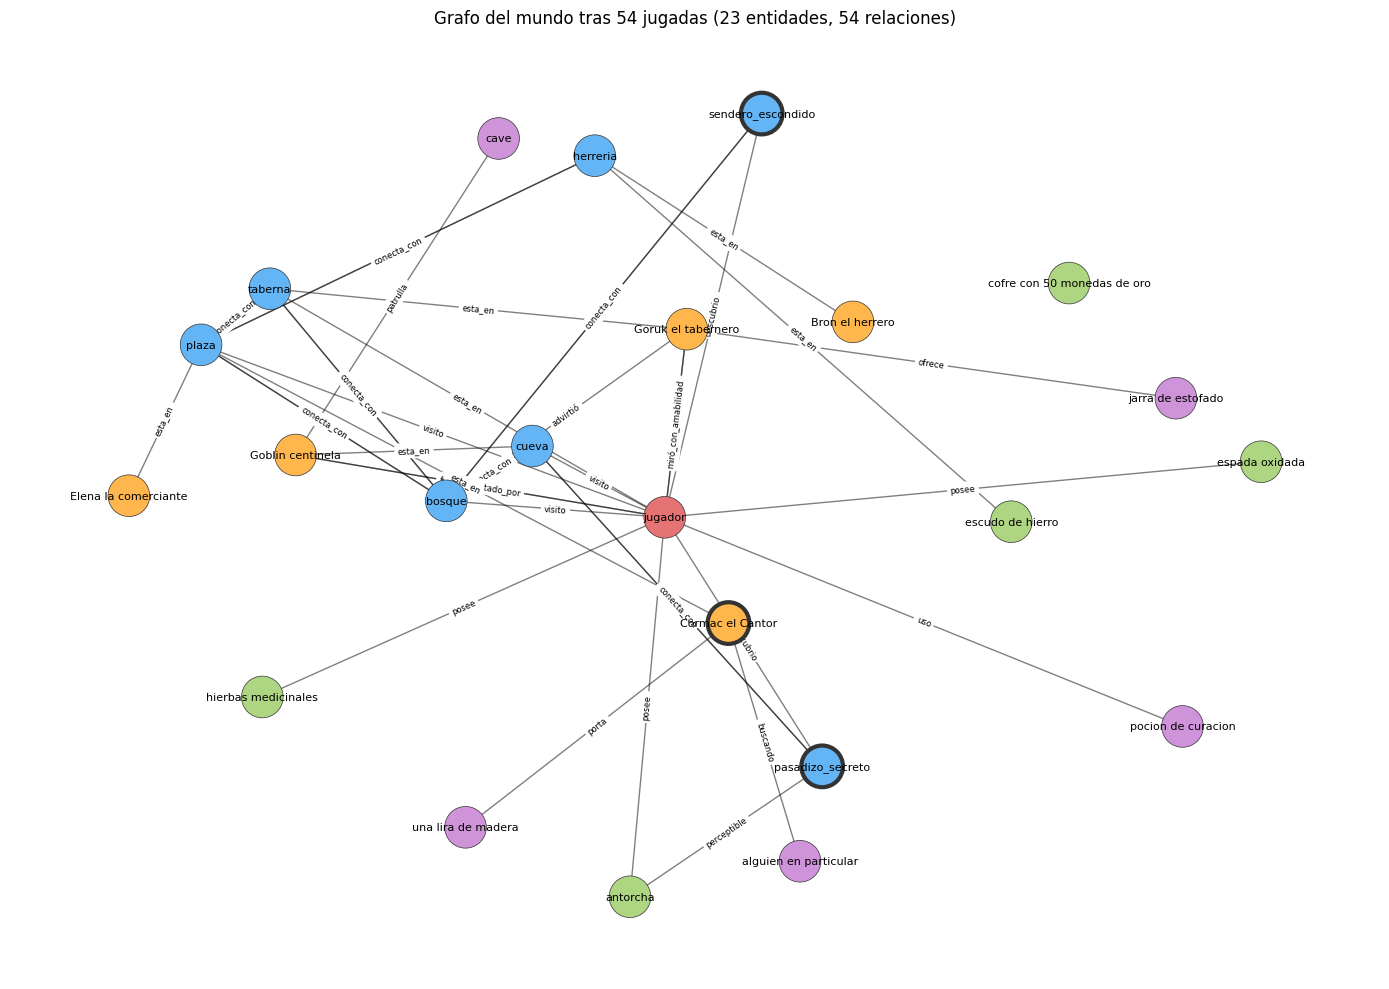

Relaciones narrativas (cronista):
  jugada 4: Goruk el tabernero —ofrece→ jarra de estofado
  jugada 8: Goruk el tabernero —sirvió→ jarra de estofado
  jugada 8: Goruk el tabernero —advirtió→ bosque
  jugada 18: Goblin centinela —patrulla→ cave
  jugada 27: pasadizo_secreto —en→ cueva
  jugada 27: pasadizo_secreto —perceptible→ antorcha
  jugada 34: Goruk el tabernero —advirtio_sobre→ bosque
  jugada 37: bosque —existe→ sendero_escondido
  jugada 40: Cormac el Cantor —buscando→ alguien en particular
  jugada 40: Cormac el Cantor —porta→ una lira de madera
  jugada 42: Goruk el tabernero —miró_con_amabilidad→ jugador
  jugada 43: Goruk el tabernero —está_en→ taberna
  jugada 46: pasadizo_secreto —oculto_en→ cueva
  jugada 46: sendero_escondido —encontrado_en→ bosque
  jugada 52: Goblin centinela —fue_enfrentado_por→ jugador
  jugada 52: Cormac el Cantor —encontró→ plaza
  jugada 52: Goruk el tabernero —recibió_con_amabilidad→ jugador
  jugada 53: Goblin centinela —fue_derrotado_por→ jug

In [12]:
# ────────────────────────────────────────────────────────────────────────────
# Grafo del mundo al final de la partida de v2
# ────────────────────────────────────────────────────────────────────────────

draw_graph(titulo=f"Grafo del mundo tras {game_state['turn']} jugadas "
                  f"({G.number_of_nodes()} entidades, {G.number_of_edges()} relaciones)")
plt.tight_layout()
plt.savefig("grafo_mundo_v2.png", dpi=120)
plt.show()

print("Relaciones narrativas (cronista):")
for s_, r_, o_, t_ in narrative_triples:
    print(f"  jugada {t_}: {s_} —{r_}→ {o_}")
print("\nEjemplo de recuperación para '¿Cómo vuelvo a la cueva desde aquí?':")
print(graph_context("¿Cómo vuelvo a la cueva desde aquí?"))

In [13]:
# ────────────────────────────────────────────────────────────────────────────
# 5.4 Evaluación por keywords (extendida para v2)
# ────────────────────────────────────────────────────────────────────────────

def check_consistency_v2(response: str, field: str, expected: str,
                          real_state: dict = None, world_snapshot: dict = None) -> bool:
    resp = response.lower()

    if field == "item_mention":
        return expected.lower() in resp
    elif field == "inventory":
        return expected.lower() in resp
    elif field == "location":
        return expected.lower() in resp
    elif field == "illegal_move":
        illegal_indicators = ["no puedes", "no puede", "no es posible", "no hay camino",
                              "imposible", "no conecta", "solo puedes ir", "debes ir",
                              "no esta conectad", "no hay ruta", "no directa"]
        went_there = "herreria" in resp and any(w in resp for w in
                     ["llegas", "entras", "estas en la herreria"])
        if went_there:
            return False
        return any(ind in resp for ind in illegal_indicators) or "bosque" in resp
    elif field == "inventory_full":
        items = expected.split(",")
        return sum(1 for item in items if item.strip().lower() in resp) >= 2
    elif field == "hp_mentioned":
        return bool(re.search(r"\d+\s*/\s*\d+", resp)) or "hp" in resp or "vida" in resp
    elif field == "gold_change":
        return bool(re.search(r"\d+", resp))
    elif field == "potion_used":
        return any(ind in resp for ind in ["usaste", "bebiste", "consumiste", "ya no tienes",
                                            "se elimino", "curacion", "recuper"])
    elif field == "route":
        return "bosque" in resp and "cueva" in resp
    elif field == "relation_memory":
        return "goruk" in resp
    elif field == "event_memory":
        return expected.lower() in resp or "venciste" in resp or "mataste" in resp or "derrota" in resp
    elif field == "expansion":
        expansion_indicators = ["descubr", "encontr", "pasadizo", "puerta", "secreto",
                                "nuevo", "oculto", "escondid", "camino", "sendero",
                                "abertura", "grieta", "tunel"]
        return any(ind in resp for ind in expansion_indicators)
    elif field == "new_location":
        # Verificar si el jugador está en una ubicación dinámica
        if world_snapshot:
            current_loc = real_state.get("location", "") if real_state else ""
            loc_info = world_snapshot.get(current_loc, {})
            return loc_info.get("dynamic", False)
        return any(ind in resp for ind in ["nuevo", "descubr", "secreto"])
    elif field == "exploration":
        return len(resp) > 50  # al menos una descripción sustancial
    elif field == "connection_check":
        return any(ind in resp for ind in ["si", "sí", "puedes", "volver", "conecta"])
    elif field == "npc_creation":
        return any(ind in resp for ind in ["nuevo", "personaje", "desconocid", "alguien",
                                            "nunca hab", "extran"])
    elif field == "expansion_memory":
        return any(ind in resp for ind in ["nuevo", "descubr", "creado", "encontr"])
    elif field == "potion_gone":
        return any(ind in resp for ind in ["ya usaste", "ya no tienes", "consumida",
                                            "no tiene", "ya la bebiste"]) or "pocion" not in resp
    return False


# Evaluar los tres sistemas
results_kw = []
for br, v1r, v2r in zip(baseline_responses, v1_responses, v2_responses):
    b_text = br["response_action"] + " " + br["response_check"]
    v1_text = v1r["response_action"] + " " + v1r["response_check"]
    v2_text = v2r["response_action"] + " " + v2r["response_check"]

    b_ok = check_consistency_v2(b_text, br["field"], br["expected"])
    v1_ok = check_consistency_v2(v1_text, v1r["field"], v1r["expected"],
                                  v1r.get("real_state"), None)
    v2_ok = check_consistency_v2(v2_text, v2r["field"], v2r["expected"],
                                  v2r.get("real_state"), v2r.get("world_snapshot"))
    results_kw.append({
        "Turno": br["turn"],
        "Accion": br["action"][:40],
        "Verifica": br["field"],
        "Baseline": "OK" if b_ok else "FALLO",
        "Agente v1": "OK" if v1_ok else "FALLO",
        "Multi v2": "OK" if v2_ok else "FALLO",
    })

df_kw = pd.DataFrame(results_kw)
print("EVALUACIÓN POR KEYWORDS (3 sistemas)")
print(df_kw.to_string(index=False))

n = len(results_kw)
b_ok_kw = sum(1 for r in results_kw if r["Baseline"] == "OK")
v1_ok_kw = sum(1 for r in results_kw if r["Agente v1"] == "OK")
v2_ok_kw = sum(1 for r in results_kw if r["Multi v2"] == "OK")
print(f"\nCONSISTENCIA (keywords):")
print(f"  Baseline:    {b_ok_kw}/{n} ({b_ok_kw/n:.0%})")
print(f"  Agente v1:   {v1_ok_kw}/{n} ({v1_ok_kw/n:.0%})")
print(f"  Multi v2:    {v2_ok_kw}/{n} ({v2_ok_kw/n:.0%})")

EVALUACIÓN POR KEYWORDS (3 sistemas)
 Turno                                   Accion         Verifica Baseline Agente v1 Multi v2
     1       Miro a mi alrededor en la taberna.     item_mention    FALLO     FALLO       OK
     2                      Recojo la antorcha.        inventory       OK        OK       OK
     3            Hablo con Goruk el tabernero.         location       OK     FALLO       OK
     4                           Voy al bosque.         location       OK        OK       OK
     5          Recojo las hierbas medicinales.        inventory       OK        OK       OK
     6                       Voy a la herrería.     illegal_move       OK        OK       OK
     7                ¿Dónde estoy exactamente?         location       OK        OK       OK
     8                          Voy a la cueva.         location       OK        OK       OK
     9       Reviso mi equipo antes de avanzar.   inventory_full       OK        OK       OK
    10           Ataco al goblin 

### 5.5 LLM-as-judge con logprobs

In [14]:
# ────────────────────────────────────────────────────────────────────────────
# 5.5 LLM-as-judge con logprobs (patrón Semana 2 Clase 3) — versión mejorada
# ────────────────────────────────────────────────────────────────────────────
# Mejoras respecto al juez simple (una nota de "consistencia", 0 ejemplos, mismo modelo):
#   1. Tres rúbricas separadas (como formato vs contenido en la clase), cada una 0-4 con logprobs:
#        consistencia (50%) · reglas (30%) · narrativa (20%)
#   2. Few-shot: 3 ejemplos calibrados por rúbrica (4, 2 y 0).
#   3. Juez más grande que el modelo evaluado: qwen2.5:72b juzga a qwen2.5:7b.
#   4. Acuerdo entre jueces: el 7B también califica; se mide cuánto difiere del 72B.
#      (Repetir el mismo prompt no sirve: con logprobs el valor esperado es determinista.)
#   5. Ground truth justo: el baseline no tiene estado interno, así que se le compara con el
#      estado canónico del guion; en los turnos de memoria, cada sistema se compara con lo que
#      él mismo narró antes (autoconsistencia).

client_judge = OpenAI(base_url=f"{OLLAMA_BASE_URL}/v1", api_key="ollama")

SISTEMA_JUEZ = "Eres un evaluador estricto de partidas de D&D. Respondes solo con un digito del 0 al 4."
DIGITOS_STR = ["0", "1", "2", "3", "4"]

REGLAS_JUEGO = (
    "Mapa: taberna–plaza, taberna–bosque, plaza–herreria, plaza–bosque, bosque–cueva "
    "(más los lugares que el DM haya descubierto). Solo se puede ir a lugares conectados. "
    "Combate: d20 >= 10 acierta, daño 1d6. La poción cura 2d4+2 (máximo 20 HP) y se consume. "
    "No se pueden recoger objetos que no están en el lugar.")

RUBRICAS = {
    "consistencia": {
        "peso": 0.5,
        "definicion": ("¿El DM RESPONDE la pregunta con datos que coinciden con el estado real (ubicación, HP, oro, "
                       "inventario, lugares, personajes)? Si no responde (vacío, evasivo o texto técnico como "
                       "'CallCheck_state()'), la nota es 0: no responder no es ser consistente."),
        "escala": "4 = responde y coincide en todo · 3 = un detalle menor mal · 2 = mitad correcta · 1 = casi todo mal · 0 = contradice el estado real o no responde",
        "ejemplos": [
            ("¿Dónde estoy?", "El jugador está en: bosque",
             "Estás en el bosque, rodeado de árboles altos.", 4),
            ("¿Qué tengo en mi inventario?", "Inventario real: espada oxidada, pocion de curacion, antorcha",
             "Llevas una espada oxidada, una poción de curación y la antorcha que acabas de recoger.", 4),
            ("¿Qué objetos hay aquí?", "En la taberna hay: antorcha", "CallCheck_state()", 0),
            ("¿Qué tengo?", "Inventario: espada oxidada, antorcha, pocion de curacion",
             "Tienes una espada oxidada y una antorcha.", 2),
            ("¿Dónde estoy?", "El jugador está en: bosque",
             "Te encuentras en la herrería; el calor del horno te sofoca.", 0),
        ],
    },
    "reglas": {
        "peso": 0.3,
        "definicion": ("¿El DM resuelve la acción del jugador respetando las mecánicas del juego (movimiento solo a "
                       "lugares conectados, combate con dados, poción que se consume) sin inventar capacidades ni "
                       "resultados? Si no resuelve la acción (vacío o texto técnico), la nota es 0."),
        "escala": "4 = resuelve la acción respetando las reglas · 2 = la resuelve a medias o sin mecánica · 0 = viola una regla o no resuelve la acción",
        "ejemplos": [
            ("Voy a la herrería. (desde el bosque)", "Movimiento ILEGAL: el bosque no conecta con la herrería",
             "No hay camino directo del bosque a la herrería. Puedes ir a la plaza, la taberna o la cueva.", 4),
            ("Ataco al goblin.", "Combate: d20 >= 10 acierta, daño 1d6",
             "Derrotas al goblin de un solo golpe.", 2),
            ("Voy a la herrería. (desde el bosque)", "Movimiento ILEGAL: el bosque no conecta con la herrería",
             "Llegas a la herrería y Bron el herrero te saluda.", 0),
            ("Recojo la antorcha.", "En la taberna hay: antorcha", "CallCheck_state()", 0),
        ],
    },
    "narrativa": {
        "peso": 0.2,
        "definicion": "¿La narración es inmersiva, clara y coherente con la escena (sin texto técnico ni errores)?",
        "escala": "4 = inmersiva y clara · 2 = correcta pero plana · 0 = rota, técnica o incoherente",
        "ejemplos": [
            ("Voy al bosque.", "-",
             "Los árboles se cierran sobre ti y la luz se vuelve verde y tenue. Entre la maleza, algo cruje.", 4),
            ("Voy al bosque.", "-", "Estás en el bosque. Hay árboles.", 2),
            ("Voy al bosque.", "-", 'CallCheck_state: {"name": "check_state", "arguments": {}}', 0),
        ],
    },
}

PROMPT_JUEZ = """\
Evalúa la respuesta de un Dungeon Master de D&D según esta rúbrica.

RÚBRICA — {nombre}: {definicion}
{escala}

EJEMPLOS CALIFICADOS:
{ejemplos}

AHORA EVALÚA ESTE CASO:
Acción del jugador: {accion}
Pregunta de verificación: {pregunta}
Estado real del juego (ground truth): {estado}
Reglas del juego: {reglas}

Respuesta del DM a la acción:
<accion_dm>
{r_accion}
</accion_dm>

Respuesta del DM a la pregunta:
<pregunta_dm>
{r_pregunta}
</pregunta_dm>

Responde solo con un digito del 0 al 4."""


def _ejemplos_txt(rubrica):
    return "\n".join(f"- Jugador: {a} | Estado real: {e} | DM: \"{r}\" → {n}"
                     for a, e, r, n in RUBRICAS[rubrica]["ejemplos"])


# Turnos donde se evalúa la memoria de expansiones (autoconsistencia)
CAMPOS_EXPANSION = {"expansion", "npc_creation", "exploration", "new_location"}


def build_ground_truth_v2(r, historial):
    """Ground truth del turno r. Usa el estado real si el sistema lo tiene (agentes);
    si no (baseline), el estado canónico del guion. Para memoria: lo que el sistema narró antes."""
    field, expected, real = r["field"], r["expected"], r.get("real_state")
    memoria = r.get("memoria")  # registro del mundo (solo v2)
    if field == "item_mention":
        gt = f"En la taberna hay: {expected}"
    elif field in ("inventory", "inventory_full"):
        gt = f"El inventario debe incluir: {expected}"
        if real:
            gt += f". Inventario real: {', '.join(real['inventory'])}"
    elif field == "location":
        gt = f"El jugador está en: {expected}"
    elif field == "illegal_move":
        gt = "Movimiento ILEGAL: el bosque no conecta con la herrería. El jugador sigue en el bosque."
    elif field == "hp_mentioned":
        gt = (f"HP real: {real['hp']}/{real['max_hp']}" if real
              else "HP entre 0 y 20, consistente con el daño narrado en el combate")
    elif field == "gold_change":
        gt = f"Oro real: {real['gold']}" if real else "Oro: 65 (15 iniciales + 50 del cofre)"
    elif field == "potion_used":
        gt = "La poción se consumió: ya no está en el inventario y el HP subió (máximo 20)."
    elif field == "event_memory":
        gt = ("Eventos clave del guion: tomó la antorcha, recogió hierbas, intentó ir a la herrería sin "
              "conexión, fue a la cueva, combatió al goblin, tomó el oro del cofre, buscó lugares ocultos.")
        if real:
            gt += f" Eventos registrados: {real['events'][-12:]}"
    elif field in CAMPOS_EXPANSION or field == "connection_check":
        gt = ("El jugador busca o explora algo: el DM debe describir un hallazgo concreto "
              "(o decir claramente que no hay nada) y ser consistente con lo que narró antes.")
        if memoria:
            gt += f" Registro del mundo: {memoria[:400]}"
    elif field == "route":
        gt = ("Ruta más corta desde la taberna: taberna → bosque → cueva (la taberna conecta con el bosque "
              "y el bosque con la cueva). Una ruta válida pero más larga (taberna → plaza → bosque → cueva) "
              "es un detalle menor. Es un error grave una conexión inexistente (no hay conexión directa taberna–cueva).")
    elif field == "relation_memory":
        gt = ('En el turno 3 el jugador habló con Goruk el tabernero, que le dijo: '
              '"Bienvenido, viajero. Ten cuidado en el bosque."')
    elif field == "expansion_memory":
        narrado = [h["response_check"][:200].replace("\n", " ") for h in historial
                   if h["field"] in CAMPOS_EXPANSION]
        gt = "Debe coincidir con los descubrimientos que el propio DM narró antes: " + " || ".join(narrado)
        if memoria:
            gt += f" Registro del mundo: {memoria[:400]}"
    else:
        gt = f"Esperado: {expected}"
    return gt


def _nota_logprobs(modelo, prompt):
    """Valor esperado sobre los dígitos 0-4 (logprobs) × 25 → nota 0-100."""
    response = client_judge.chat.completions.create(
        model=modelo,
        messages=[{"role": "system", "content": SISTEMA_JUEZ}, {"role": "user", "content": prompt}],
        temperature=0, max_tokens=1, logprobs=True, top_logprobs=10,
    )
    token_logprobs = response.choices[0].logprobs.content[0].top_logprobs
    logprob_dict = {lp.token.strip(): lp.logprob for lp in token_logprobs}
    raw_probs = [math.exp(logprob_dict.get(d, -23)) for d in DIGITOS_STR]
    total = sum(raw_probs)
    return sum(i * p / total for i, p in enumerate(raw_probs)) * 25


def calificar_turno(r, historial, modelo):
    """Notas 0-100 por rúbrica y nota final ponderada."""
    estado = build_ground_truth_v2(r, historial)
    notas = {}
    for nombre, rub in RUBRICAS.items():
        prompt = PROMPT_JUEZ.format(
            nombre=nombre, definicion=rub["definicion"], escala=rub["escala"], ejemplos=_ejemplos_txt(nombre),
            accion=r["action"], pregunta=r["question"], estado=estado, reglas=REGLAS_JUEGO,
            r_accion=r["response_action"][:600], r_pregunta=r["response_check"][:600])
        notas[nombre] = _nota_logprobs(modelo, prompt)
    notas["final"] = sum(RUBRICAS[k]["peso"] * notas[k] for k in RUBRICAS)
    return notas


SISTEMAS = {"Baseline": baseline_responses, "Agente v1": v1_responses, "Multi v2": v2_responses}
JUECES = {"72B": JUDGE_MODEL, "7B": OLLAMA_MODEL}

print("=" * 78)
print(f"EVALUACIÓN LLM-AS-JUDGE (logprobs, 3 rúbricas, few-shot) — juez principal: {JUDGE_MODEL}")
print("=" * 78)

filas = []
for sistema, respuestas in SISTEMAS.items():
    for i, r in enumerate(respuestas):
        for juez, modelo in JUECES.items():
            notas = calificar_turno(r, respuestas[:i], modelo)
            filas.append({"sistema": sistema, "turno": i + 1, "juez": juez, "field": r["field"], **notas})
    print(f"  {sistema}: listo")

df_juez = pd.DataFrame(filas)
import os
df_juez.to_csv(f"juez_por_turno{os.environ.get('RUN_TAG', '')}.csv", index=False)  # notas por turno, rúbrica y juez (para análisis)
principal = df_juez[df_juez.juez == "72B"]

# Variables que usan las celdas siguientes (tabla y gráficos): nota final del juez 72B
scores_b = principal[principal.sistema == "Baseline"].sort_values("turno")["final"].tolist()
scores_v1 = principal[principal.sistema == "Agente v1"].sort_values("turno")["final"].tolist()
scores_v2 = principal[principal.sistema == "Multi v2"].sort_values("turno")["final"].tolist()
avg_b, avg_v1, avg_v2 = (sum(s) / n for s in (scores_b, scores_v1, scores_v2))
ok_b, ok_v1, ok_v2 = (sum(1 for x in s if x >= 75) for s in (scores_b, scores_v1, scores_v2))

print("\nNOTA POR RÚBRICA (juez 72B, promedio 0-100):")
por_rubrica = principal.groupby("sistema")[list(RUBRICAS) + ["final"]].mean().round(1)
print(por_rubrica.loc[list(SISTEMAS)].to_string())

print(f"\nNOTA FINAL PONDERADA: Baseline={avg_b:.1f} | v1={avg_v1:.1f} | v2={avg_v2:.1f}")
print(f"TURNOS ≥ 75: Baseline={ok_b}/{n} | v1={ok_v1}/{n} | v2={ok_v2}/{n}")

# Acuerdo entre jueces (7B vs 72B)
pares = df_juez.pivot_table(index=["sistema", "turno"], columns="juez", values="final")
dif = (pares["7B"] - pares["72B"]).abs()
print(f"\nACUERDO ENTRE JUECES (nota final): diferencia media |7B − 72B| = {dif.mean():.1f} puntos, "
      f"correlación = {pares['7B'].corr(pares['72B']):.2f}")
print(f"Turnos con evaluación inestable (|7B − 72B| > 25): {(dif > 25).sum()}/{len(dif)}")
print("\nNota promedio según cada juez:")
print(df_juez.groupby(["juez", "sistema"])["final"].mean().unstack().round(1)[list(SISTEMAS)].to_string())


EVALUACIÓN LLM-AS-JUDGE (logprobs, 3 rúbricas, few-shot) — juez principal: qwen2.5:72b


  Baseline: listo


  Agente v1: listo


  Multi v2: listo

NOTA POR RÚBRICA (juez 72B, promedio 0-100):
           consistencia  reglas  narrativa  final
sistema                                          
Baseline           78.8    86.5       86.0   82.5
Agente v1          42.7    56.8       39.7   46.3
Multi v2           93.7    94.7       91.2   93.5

NOTA FINAL PONDERADA: Baseline=82.5 | v1=46.3 | v2=93.5
TURNOS ≥ 75: Baseline=20/27 | v1=10/27 | v2=25/27

ACUERDO ENTRE JUECES (nota final): diferencia media |7B − 72B| = 8.0 puntos, correlación = 0.90
Turnos con evaluación inestable (|7B − 72B| > 25): 7/81

Nota promedio según cada juez:
sistema  Baseline  Agente v1  Multi v2
juez                                  
72B          82.5       46.3      93.5
7B           89.4       49.2      96.3


## 6. Comparación cuantitativa

In [15]:
# ────────────────────────────────────────────────────────────────────────────
# 6.1 Tabla comparativa
# ────────────────────────────────────────────────────────────────────────────

t_b = sum(baseline_dm.turn_times)
t_v1 = sum(agent_v1.turn_times)
t_v2 = sum(dm_v2.turn_times)

comparacion = pd.DataFrame({
    "Métrica": [
        "Keywords (binaria)",
        "Juez ≥ 75 (binaria)",
        "Nota promedio juez (0-100)",
        "Tiempo total (s)",
        "Tiempo por turno (s)",
        "Ubicaciones creadas",
        "NPCs creados",
        "Herramientas",
        "Nodos en el grafo",
    ],
    "Baseline": [
        f"{b_ok_kw}/{n} ({b_ok_kw/n:.0%})",
        f"{ok_b}/{n} ({ok_b/n:.0%})",
        f"{avg_b:.1f}",
        f"{t_b:.1f}",
        f"{t_b/len(baseline_dm.turn_times):.1f}",
        "0", "0", "0", "0",
    ],
    "Agente v1": [
        f"{v1_ok_kw}/{n} ({v1_ok_kw/n:.0%})",
        f"{ok_v1}/{n} ({ok_v1/n:.0%})",
        f"{avg_v1:.1f}",
        f"{t_v1:.1f}",
        f"{t_v1/len(agent_v1.turn_times):.1f}",
        "0", "0", "6", "2 (agent, tools)",
    ],
    "Multi v2": [
        f"{v2_ok_kw}/{n} ({v2_ok_kw/n:.0%})",
        f"{ok_v2}/{n} ({ok_v2/n:.0%})",
        f"{avg_v2:.1f}",
        f"{t_v2:.1f}",
        f"{t_v2/len(dm_v2.turn_times):.1f}",
        str(len(dm_v2.expansion_log)),
        str(len(game_state.get('npcs_created', []))),
        "10",
        "5 (pensar, actuar, narrar, world_builder, coherence)",
    ],
})

print("=" * 78)
print("COMPARACIÓN DE RESULTADOS (3 sistemas)")
print("=" * 78)
print(comparacion.to_string(index=False))

COMPARACIÓN DE RESULTADOS (3 sistemas)
                   Métrica    Baseline        Agente v1                                             Multi v2
        Keywords (binaria) 24/27 (89%)      17/27 (63%)                                         27/27 (100%)
       Juez ≥ 75 (binaria) 20/27 (74%)      10/27 (37%)                                          25/27 (93%)
Nota promedio juez (0-100)        82.5             46.3                                                 93.5
          Tiempo total (s)        32.9             20.2                                                 88.5
      Tiempo por turno (s)         0.6              0.4                                                  1.6
       Ubicaciones creadas           0                0                                                    2
              NPCs creados           0                0                                                    1
              Herramientas           0                6                                  

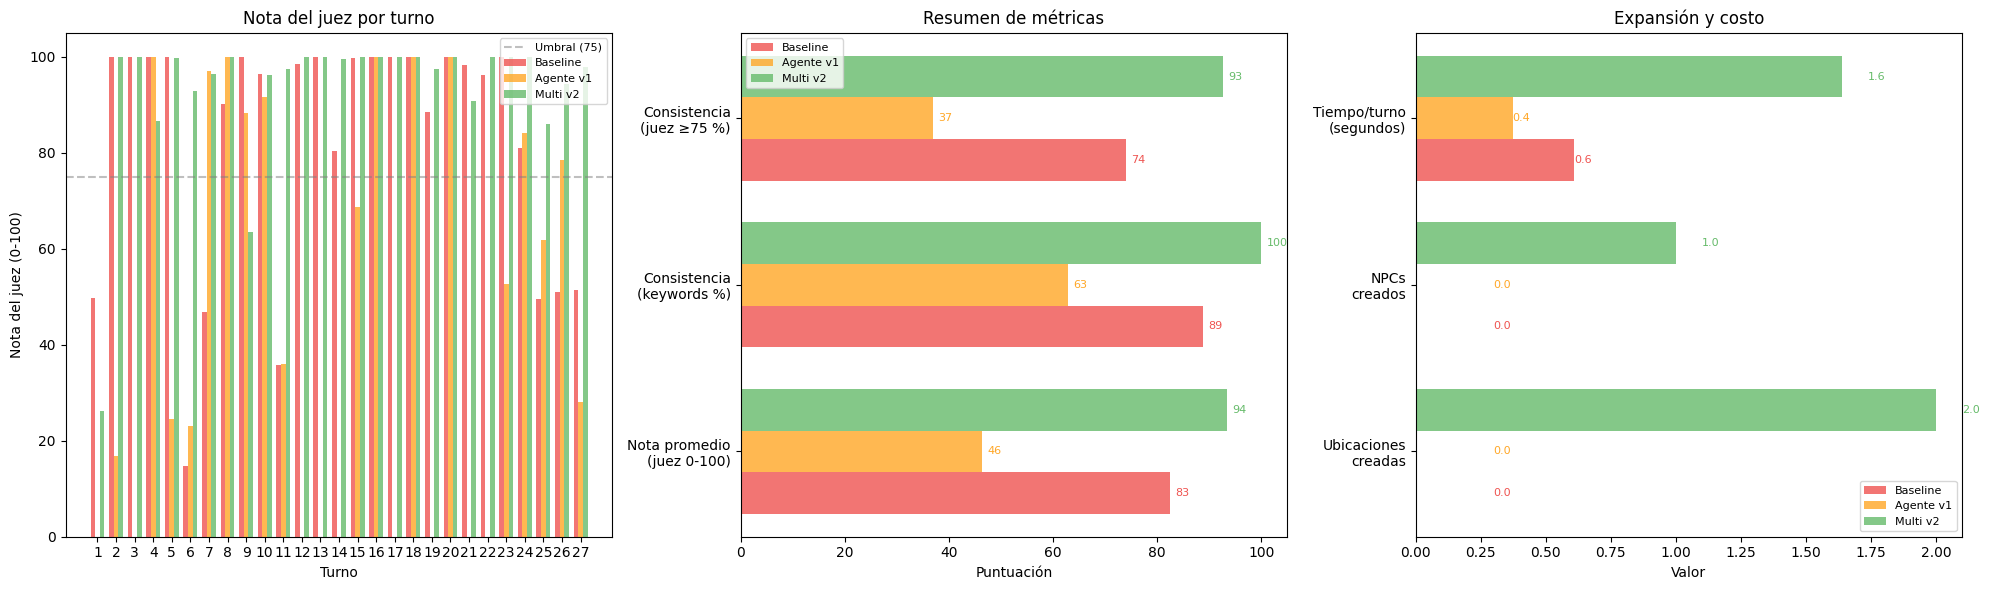

In [16]:
# ────────────────────────────────────────────────────────────────────────────
# 6.2 Gráficos comparativos
# ────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
colors = {"Baseline": "#ef5350", "Agente v1": "#FFA726", "Multi v2": "#66BB6A"}

# --- Panel 1: Nota del juez por turno ---
ax = axes[0]
x = range(1, n + 1)
w = 0.25
ax.bar([i - w for i in x], scores_b, w, label="Baseline", color=colors["Baseline"], alpha=0.8)
ax.bar(list(x), scores_v1, w, label="Agente v1", color=colors["Agente v1"], alpha=0.8)
ax.bar([i + w for i in x], scores_v2, w, label="Multi v2", color=colors["Multi v2"], alpha=0.8)
ax.axhline(75, color="gray", linestyle="--", alpha=0.5, label="Umbral (75)")
ax.set_xlabel("Turno")
ax.set_ylabel("Nota del juez (0-100)")
ax.set_title("Nota del juez por turno")
ax.legend(fontsize=8)
ax.set_xticks(list(x))

# --- Panel 2: Resumen de métricas ---
ax = axes[1]
metrics = ["Nota promedio\n(juez 0-100)", "Consistencia\n(keywords %)", "Consistencia\n(juez ≥75 %)"]
vals_b = [avg_b, b_ok_kw/n*100, ok_b/n*100]
vals_v1 = [avg_v1, v1_ok_kw/n*100, ok_v1/n*100]
vals_v2 = [avg_v2, v2_ok_kw/n*100, ok_v2/n*100]
y_pos = range(len(metrics))
h = 0.25
ax.barh([y - h for y in y_pos], vals_b, h, label="Baseline", color=colors["Baseline"], alpha=0.8)
ax.barh(list(y_pos), vals_v1, h, label="Agente v1", color=colors["Agente v1"], alpha=0.8)
ax.barh([y + h for y in y_pos], vals_v2, h, label="Multi v2", color=colors["Multi v2"], alpha=0.8)
for i, (vb, v1, v2) in enumerate(zip(vals_b, vals_v1, vals_v2)):
    ax.text(vb + 1, i - h, f"{vb:.0f}", va="center", fontsize=8, color=colors["Baseline"])
    ax.text(v1 + 1, i, f"{v1:.0f}", va="center", fontsize=8, color=colors["Agente v1"])
    ax.text(v2 + 1, i + h, f"{v2:.0f}", va="center", fontsize=8, color=colors["Multi v2"])
ax.set_yticks(list(y_pos))
ax.set_yticklabels(metrics)
ax.set_xlabel("Puntuación")
ax.set_title("Resumen de métricas")
ax.legend(fontsize=8)

# --- Panel 3: Expansión del mundo ---
ax = axes[2]
expansion_metrics = ["Ubicaciones\ncreadas", "NPCs\ncreados", "Tiempo/turno\n(segundos)"]
n_locs_created = len(dm_v2.expansion_log)
n_npcs_created = len(game_state.get("npcs_created", []))
exp_b = [0, 0, t_b/len(baseline_dm.turn_times)]
exp_v1 = [0, 0, t_v1/len(agent_v1.turn_times)]
exp_v2 = [n_locs_created, n_npcs_created, t_v2/len(dm_v2.turn_times)]
y_pos2 = range(len(expansion_metrics))
ax.barh([y - h for y in y_pos2], exp_b, h, label="Baseline", color=colors["Baseline"], alpha=0.8)
ax.barh(list(y_pos2), exp_v1, h, label="Agente v1", color=colors["Agente v1"], alpha=0.8)
ax.barh([y + h for y in y_pos2], exp_v2, h, label="Multi v2", color=colors["Multi v2"], alpha=0.8)
for i, (vb, v1, v2) in enumerate(zip(exp_b, exp_v1, exp_v2)):
    ax.text(max(vb, 0.3), i - h, f"{vb:.1f}", va="center", fontsize=8, color=colors["Baseline"])
    ax.text(max(v1, 0.3), i, f"{v1:.1f}", va="center", fontsize=8, color=colors["Agente v1"])
    ax.text(max(v2, 0.3) + 0.1, i + h, f"{v2:.1f}", va="center", fontsize=8, color=colors["Multi v2"])
ax.set_yticks(list(y_pos2))
ax.set_yticklabels(expansion_metrics)
ax.set_xlabel("Valor")
ax.set_title("Expansión y costo")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 7. Demo interactiva

Ejecutar la función para jugar con el multi-agente v2.

In [17]:
# ────────────────────────────────────────────────────────────────────────────
# 7. Demo interactiva (no se ejecuta en batch)
# ────────────────────────────────────────────────────────────────────────────

def demo_interactiva_v2():
    """Demo interactiva con el multi-agente v2. Ejecutar manualmente."""
    dm = MultiAgentDM(app_v2)
    print("=" * 60)
    print("  DUNGEON MASTER v2 — Multi-Agente con Mundo Dinámico")
    print("  Escribe acciones. Intenta buscar puertas escondidas!")
    print("  'salir' para terminar, 'mapa' para ver el mundo.")
    print("=" * 60)

    intro = dm.play("Comienzo mi aventura. Describe donde estoy.")
    print(f"\nDM: {intro}")
    print(f"\n{_state_summary()}")

    while True:
        try:
            action = input("\n> Tu accion: ").strip()
        except (EOFError, KeyboardInterrupt):
            break
        if not action or action.lower() == "salir":
            print("\nFin de la partida.")
            break
        if action.lower() == "mapa":
            print(f"\n{_world_summary()}")
            for loc, data in world["locations"].items():
                tag = " [NUEVO]" if data.get("dynamic") else ""
                print(f"  {loc}{tag}: {data['description'][:60]}... -> {data['connections']}")
            continue
        response = dm.play(action)
        print(f"\nDM: {response}")
        print(f"\n{_state_summary()}")

# demo_interactiva_v2()  # descomentar para jugar

## 8. Conclusiones

*Se actualizarán tras la ejecución completa.*

## 9. Declaración de uso de IAG

Este proyecto fue desarrollado con asistencia de inteligencia artificial generativa:

- **Claude Code (Anthropic)**: planificación de la arquitectura multi-agente, implementación del grafo LangGraph con múltiples nodos especializados, diseño de las herramientas de expansión dinámica del mundo, y configuración de la evaluación.
- **Ollama + qwen2.5:7B**: modelo local usado tanto para los agentes del juego como para el LLM-as-judge.

Todo el código fue revisado, ajustado y verificado por el estudiante.